# **Improving Employee Retention By Predicting Employee Attrition Using Machine Learning**

## 📌 Problem Statement

An Indonesian technology company loses roughly **31% of its employees** to resignation. HR cannot tell which employees are most likely to leave, so retention conversations, stay interviews, and engagement budgets are spread evenly instead of being focused where they can change an outcome. The cost is not only hiring and onboarding, but lost team knowledge and delayed delivery.

## 📌 Goals

- Build a model that ranks employees by resignation risk so HR can prioritize retention outreach. (**MAIN**)
- Identify the profile and engagement factors most associated with attrition. (**SECONDARY**)
- Ship a Streamlit app that scores one employee or a batch and explains the score. (**DEPLOYMENT**)

## 📌 Objectives

- Audit and clean the HR dataset without leaking post-resignation information.
- Explore attrition patterns and quantify the signal in the available features.
- Compare six classifiers with repeated stratified cross-validation and tune them.
- Evaluate the deployed model honestly, including a majority-class baseline and a cumulative-gains analysis.
- Persist one versioned artifact that the app loads without refitting.

## 📌 Business Metrics

- **Attrition rate** — resignations divided by headcount. (**MAIN**)
- **Retention rate** — 1 − attrition rate.
- **Recall at capacity** — share of actual leavers captured when HR can only target the top N% of risk scores. (**MAIN**)
- **Lift** — recall at capacity divided by the share targeted; 1.0 is random targeting.

> **Why classification, not clustering.** `TanggalResign` gives every employee a clear binary outcome, so a supervised classifier answers the business question directly. Clustering would find groups but would not tell HR whom to prioritize. Segmentation is left for a later iteration.


# **STAGE 1 : EXPLORATORY DATA ANALYSIS (EDA)**

## Import Libraries and Settings


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)
from xgboost import XGBClassifier

from employee_attrition import schema
from employee_attrition.pipeline import (
    clean_raw,
    fit_imputation_values,
    apply_imputation_values,
    encode_features,
    align_features,
    load_artifact,
    transform_raw,
    predict_proba,
    explain_row,
)
from employee_attrition.analytics import (
    target_balance,
    attrition_by_group,
    gains_table,
    cumulative_gains_frame,
    risk_tier,
)
from utils import (
    check_data_information,
    describe_date_columns,
    describe_numerical_combined,
    describe_categorical_combined,
    identify_distribution_types,
    plot_dynamic_hisplots_kdeplots,
    plot_dynamic_boxplots_violinplots,
    plot_dynamic_countplot,
    plot_correlation_heatmap,
    calculate_correlation_tabular,
    analyze_categorical_relationships,
    calculate_vif,
    calculate_feature_importance,
    filter_outliers,
)
from utils.classification_evals_and_tuning import (
    eval_classification,
    compare_cv_metrics,
    get_model_pipeline,
    get_hyperparameters,
    tune_pipelines,
)

sns.set_style("darkgrid")
pd.set_option("display.max_columns", None)
np.random.seed(42)


### Load Dataset


In [2]:
df_raw = pd.read_csv("data/employee_performance_data.csv")
df = df_raw.copy()
df.shape


(287, 25)

In [3]:
df.sample(10)


,Username,EnterpriseID,StatusPernikahan,JenisKelamin,StatusKepegawaian,Pekerjaan,JenjangKarir,PerformancePegawai,AsalDaerah,HiringPlatform,SkorSurveyEngagement,SkorKepuasanPegawai,JumlahKeikutsertaanProjek,JumlahKeterlambatanSebulanTerakhir,JumlahKetidakhadiran,NomorHP,Email,TingkatPendidikan,PernahBekerja,IkutProgramLOP,AlasanResign,TanggalLahir,TanggalHiring,TanggalPenilaianKaryawan,TanggalResign
9,enviousMoth4,110927,Menikah,Wanita,FullTime,Software Engineer (Android),Freshgraduate_program,Sangat_bagus,Jakarta Pusat,Indeed,4,5.0,6.0,0.0,4.0,+6281391211xxx,enviousMoth4516@yahoo.com,Sarjana,1,NaN,masih_bekerja,1984-02-21,2015-3-30,2020-01-03,-
255,amazedMoth0,106363,-,Wanita,Internship,Software Engineer (Front End),Senior_level,Biasa,Jakarta Pusat,Indeed,3,5.0,0.0,0.0,12.0,+6285931209xxx,amazedMoth0683@outlook.com,Magister,1,0.0,jam_kerja,1986-08-17,2011-5-16,2014-01-10,2018-04-01
144,cautiousPonie3,105711,Bercerai,Wanita,FullTime,Software Engineer (Front End),Freshgraduate_program,Bagus,Jakarta Timur,LinkedIn,3,5.0,0.0,0.0,17.0,+6285896821xxx,cautiousPonie3736@gmail.com,Magister,1,NaN,masih_bekerja,1978-09-22,2014-07-07,2020-2-22,-
213,betrayedHeron3,110833,Belum_menikah,Pria,FullTime,Software Engineer (Back End),Senior_level,Biasa,Jakarta Timur,Diversity_Job_Fair,3,4.0,0.0,0.0,1.0,+6285814395xxx,betrayedHeron3360@hotmail.com,Sarjana,1,NaN,kejelasan_karir,1969-09-29,2011-07-11,2020-2-18,2018-04-01
230,outlyingCamel2,106467,Belum_menikah,Wanita,FullTime,Software Engineer (Back End),Mid_level,Biasa,Jakarta Timur,Employee_Referral,3,5.0,6.0,0.0,15.0,+6281380903xxx,outlyingCamel2337@icloud.com,Sarjana,1,NaN,kejelasan_karir,1981-10-11,2015-2-16,2020-2-14,2018-04-01
197,pridefulChamois9,101005,Menikah,Wanita,Outsource,Software Engineer (Back End),Senior_level,Biasa,Jakarta Selatan,LinkedIn,3,3.0,0.0,0.0,1.0,+6281276322xxx,pridefulChamois9218@proton.com,Sarjana,1,NaN,NaN,1969-09-08,2014-07-07,2020-01-11,-
97,insecureClam1,100760,Bercerai,Pria,FullTime,Software Engineer (Back End),Freshgraduate_program,Biasa,Jakarta Selatan,Indeed,4,5.0,5.0,0.0,15.0,+6289791534xxx,insecureClam1801@proton.com,Sarjana,1,NaN,masih_bekerja,1980-07-05,2011-4-15,2020-01-07,-
73,cruelCaviar1,110478,Belum_menikah,Wanita,Outsource,Software Engineer (Android),Freshgraduate_program,Sangat_kurang,Jakarta Pusat,Indeed,4,5.0,0.0,0.0,7.0,+6285654618xxx,cruelCaviar1334@outlook.com,Doktor,1,NaN,masih_bekerja,1963-05-15,2014-8-18,2020-1-21,-
109,mildAbalone7,100350,Menikah,Pria,FullTime,Product Design (UI & UX),Freshgraduate_program,Sangat_kurang,Jakarta Pusat,On-line_Web_application,4,5.0,0.0,0.0,1.0,+6285741068xxx,mildAbalone7337@hotmail.com,Sarjana,1,NaN,masih_bekerja,1977-07-15,2012-9-24,2018-03-02,-
33,madFerret4,106540,Belum_menikah,Wanita,Outsource,Software Engineer (Front End),Freshgraduate_program,Biasa,Jakarta Pusat,LinkedIn,3,3.0,6.0,0.0,7.0,+6281222388xxx,madFerret4760@hotmail.com,Magister,1,NaN,masih_bekerja,1981-04-14,2014-9-30,2020-01-07,-


In [4]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")


Number of rows: 287
Number of columns: 25


In [5]:
info_df = check_data_information(df, df.columns.tolist())
display(info_df)


,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,Username,str,0,0.00,0,0.00,0,0.0,0,0,0,285,0.9930,"spiritedPorpoise3, jealousGelding2, pluckyMues..."
1,EnterpriseID,int64,0,0.00,0,0.00,0,0.0,0,0,0,287,1.0000,"111065, 106080, 106452, 106325, 111171"
2,StatusPernikahan,str,0,0.00,0,0.00,0,0.0,0,0,0,5,0.0174,"Belum_menikah, Menikah, Bercerai, Lainnya, -"
3,JenisKelamin,str,0,0.00,0,0.00,0,0.0,0,0,0,2,0.0070,"Pria, Wanita"
4,StatusKepegawaian,str,0,0.00,0,0.00,0,0.0,0,0,0,3,0.0105,"Outsource, FullTime, Internship"
5,Pekerjaan,str,0,0.00,0,0.00,0,0.0,0,0,0,14,0.0488,"Software Engineer (Back End), Data Analyst, So..."
6,JenjangKarir,str,0,0.00,0,0.00,0,0.0,0,0,0,3,0.0105,"Freshgraduate_program, Senior_level, Mid_level"
7,PerformancePegawai,str,0,0.00,0,0.00,0,0.0,0,0,0,5,0.0174,"Sangat_bagus, Sangat_kurang, Bagus, Biasa, Kurang"
8,AsalDaerah,str,0,0.00,0,0.00,0,0.0,0,0,0,5,0.0174,"Jakarta Timur, Jakarta Utara, Jakarta Pusat, J..."
9,HiringPlatform,str,0,0.00,0,0.00,0,0.0,0,0,0,9,0.0314,"Employee_Referral, Website, Indeed, LinkedIn, ..."


## Data Understanding

**Quick overview**

- The dataset contains **287 rows and 25 columns**.
- The target is not stored directly: it must be derived from `TanggalResign` (resignation date).
- Several columns are identifiers or personal data (`Username`, `EnterpriseID`, `NomorHP`, `Email`) and must never reach the model.
- `IkutProgramLOP` is missing for **258 of 287 rows (89.9%)**; imputing it would fabricate most of the column.
- `AlasanResign` is populated only for leavers, so it leaks the target.
- `TanggalPenilaianKaryawan` is **after** `TanggalResign` for **64 of 89 leavers**, so any tenure-at-assessment feature is causally invalid for those rows.
- `PernahBekerja` is an invalid constant (one `yes`, otherwise `1`).

**Data dictionary** (generated from `employee_attrition.schema`)


In [6]:
dictionary = (
    pd.DataFrame(schema.FEATURE_DEFINITIONS)
    .T.rename_axis("Feature")
    .reset_index()
)
display(dictionary)


,Feature,description,data_type,specific_type,used_by_model,reason
0,Username,Username of the employee account,Categorical,Nominal,No,Employee identifier (PII)
1,EnterpriseID,Internal employee ID,Categorical,Nominal,No,Employee identifier (PII)
2,StatusPernikahan,Marital status of the employee,Categorical,Nominal,Yes,
3,JenisKelamin,Gender of the employee,Categorical,Nominal,Yes,
4,StatusKepegawaian,Employment status,Categorical,Nominal,Yes,
5,Pekerjaan,"Role of the employee, grouped into job families",Categorical,Nominal,Yes,
6,JenjangKarir,Career level of the employee,Categorical,Ordinal,Yes,
7,PerformancePegawai,Employee performance category,Categorical,Ordinal,Yes,
8,AsalDaerah,Employee region of origin,Categorical,Nominal,Yes,
9,HiringPlatform,Platform where the application was accepted,Categorical,Nominal,Yes,


### Date audit

`describe_date_columns` needs real datetime values, so the `-` placeholders are converted to `NaT` first.


In [7]:
df_dates = df_raw[schema.DATE_COLUMNS].copy()
for column in schema.DATE_COLUMNS:
    df_dates[column] = pd.to_datetime(
        df_dates[column].replace("-", pd.NaT),
        errors="coerce",
        format="mixed",
    )

date_summary = describe_date_columns(df_dates, schema.DATE_COLUMNS)
display(date_summary)


,count,mean,min,25%,50%,75%,max,date_range_days,date_range_months,date_range_years,unique_years,unique_months,unique_days,weekend_percentage,business_hours_percentage,most_common_month,most_common_weekday,max_gap_days,median_gap_days,future_dates_percentage,is_regular_interval
TanggalLahir,287,1979-02-14 01:15:15.679442,1951-01-02 00:00:00,1973-12-03 00:00:00,1980-09-30 00:00:00,1986-05-31 00:00:00,1992-08-17 00:00:00,15203 days 00:00:00,506.766667,41.652055,38.0,197.0,284.0,24.738676,0.0,5.0,Thursday,1353.0,25.0,0.0,False
TanggalHiring,287,2013-02-04 23:14:50.592334,2006-01-09 00:00:00,2011-07-11 00:00:00,2013-04-01 00:00:00,2014-08-18 00:00:00,2018-07-09 00:00:00,4564 days 00:00:00,152.133333,12.504110,13.0,68.0,97.0,2.439024,0.0,1.0,Monday,532.0,0.0,0.0,False
TanggalPenilaianKaryawan,287,2018-09-29 18:48:55.191637,2011-07-14 00:00:00,2017-05-03 12:00:00,2020-01-16 00:00:00,2020-02-04 00:00:00,2020-02-28 00:00:00,3151 days 00:00:00,105.033333,8.632877,10.0,46.0,127.0,18.815331,0.0,1.0,Tuesday,236.0,0.0,0.0,False
TanggalResign,89,2017-03-20 15:38:25.617977,2013-05-30 00:00:00,2015-06-15 00:00:00,2017-11-15 00:00:00,2018-06-08 00:00:00,2020-09-27 00:00:00,2677 days 00:00:00,89.233333,7.334247,8.0,34.0,52.0,26.966292,0.0,4.0,Wednesday,199.0,4.0,0.0,False


**Finding:** the assessment-date column is not safe to use. For most leavers it is recorded after their resignation date, so it cannot represent information available before the outcome. The raw dates are used only to derive age at hire and hiring year/month; the raw assessment and resignation dates are dropped.


## Initial Transformation

`clean_raw` is the same function the Streamlit app uses. It drops identifiers and leaky columns, normalises the Indonesian category labels, parses dates, derives `UsiaSaatMasuk`, `TahunHiring`, and `BulanHiring`, and creates the binary target.


In [8]:
df = clean_raw(df_raw)
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print("Model features:", len(schema.MODEL_FEATURES))
df.head()


Rows: 287 | Columns: 18
Model features: 17


,UsiaSaatMasuk,TahunHiring,BulanHiring,SkorSurveyEngagement,SkorKepuasanPegawai,JumlahKeikutsertaanProjek,JumlahKeterlambatanSebulanTerakhir,JumlahKetidakhadiran,JenisKelamin,JenjangKarir,PerformancePegawai,TingkatPendidikan,StatusPernikahan,StatusKepegawaian,Pekerjaan,AsalDaerah,HiringPlatform,StatusKerja
0,38.527036,2011,1,4,4.0,0.0,0.0,9.0,Pria,Freshgraduate Program,Sangat Bagus,Magister,Belum Menikah,Outsource,Software Engineer,Jakarta Timur,Employee Referral,0
1,29.697467,2014,1,4,4.0,4.0,0.0,3.0,Pria,Freshgraduate Program,Sangat Kurang,Sarjana,Belum Menikah,FullTime,Data & ML,Jakarta Utara,Website,1
2,37.007529,2011,1,4,3.0,0.0,0.0,11.0,Pria,Freshgraduate Program,Bagus,Magister,Menikah,FullTime,Software Engineer,Jakarta Timur,Indeed,1
3,34.234086,2014,2,3,3.0,0.0,4.0,6.0,Pria,Freshgraduate Program,Bagus,Sarjana,Belum Menikah,Outsource,Software Engineer,Jakarta Pusat,LinkedIn,0
4,39.011636,2013,11,3,3.0,0.0,0.0,11.0,Wanita,Freshgraduate Program,Bagus,Sarjana,Belum Menikah,FullTime,Product Management,Jakarta Timur,LinkedIn,1


**What was dropped and why**

| Column | Reason |
|---|---|
| `Username`, `EnterpriseID`, `NomorHP`, `Email` | Identifiers / PII |
| `PernahBekerja` | Invalid constant |
| `IkutProgramLOP` | 89.9% missing |
| `AlasanResign` | Known only after resignation; leaks the target |
| `TanggalResign` | Defines the target |
| `TanggalPenilaianKaryawan` | Recorded after resignation for most leavers |
| `TanggalLahir`, `TanggalHiring` | Replaced by `UsiaSaatMasuk`, `TahunHiring`, `BulanHiring` |


,outcome,employees
0,Still working,198
1,Resigned,89


Attrition rate: 31.0%


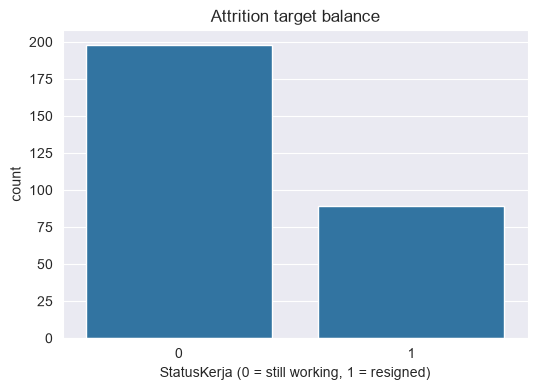

In [9]:
balance = target_balance(df)
display(balance)
print(f"Attrition rate: {df[schema.TARGET_COLUMN].mean():.1%}")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=schema.TARGET_COLUMN)
plt.title("Attrition target balance")
plt.xlabel("StatusKerja (0 = still working, 1 = resigned)")
plt.show()


The target is imbalanced at roughly **31% resigned / 69% still working**. A model that always predicts "still working" already reaches 69% accuracy, so accuracy alone is not a useful headline metric. The evaluation below uses ROC-AUC, PR-AUC, recall, and capacity-based gains.


## Univariate Analysis

### Numerical Columns


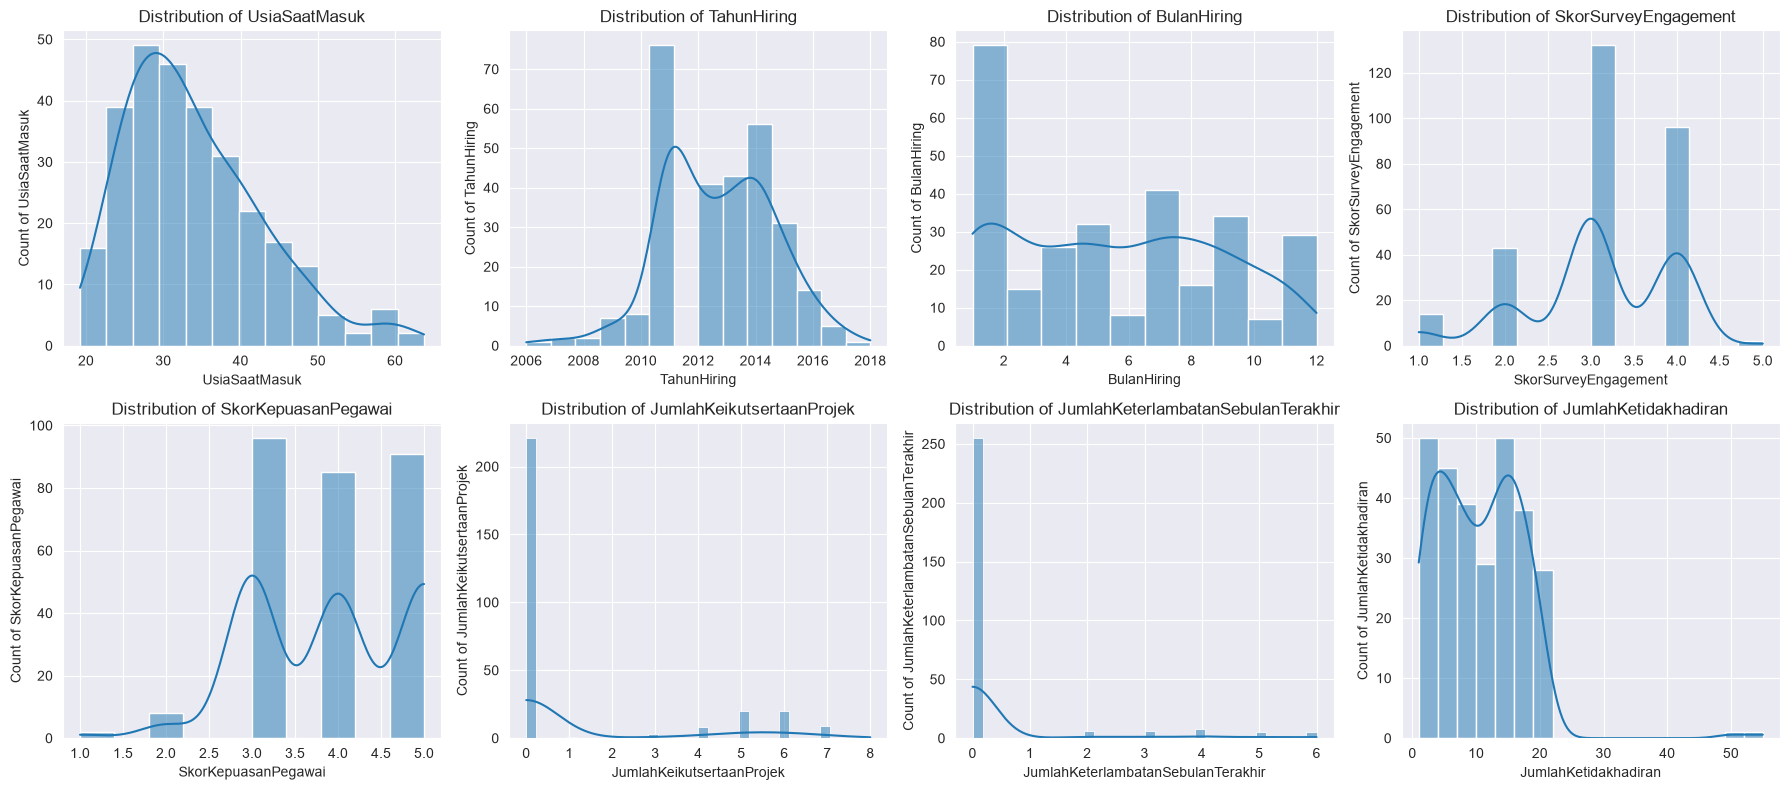

,Feature,overall_count,overall_mean,overall_std,overall_min,overall_25%,overall_50%,overall_75%,overall_max,overall_range,overall_IQR,overall_CV,overall_skewness,overall_kurtosis
0,UsiaSaatMasuk,287.0,33.976499,8.901529,19.22245,27.472964,32.238193,39.049966,63.739904,44.517454,11.577002,26.199077,0.916115,0.639025
1,TahunHiring,287.0,2012.689895,1.946308,2006.00000,2011.000000,2013.000000,2014.000000,2018.000000,12.000000,3.000000,0.096702,-0.092420,0.096018
2,BulanHiring,287.0,5.491289,3.329109,1.00000,2.000000,5.000000,8.000000,12.000000,11.000000,6.000000,60.625269,0.130550,-1.233714
3,SkorSurveyEngagement,287.0,3.101045,0.836388,1.00000,3.000000,3.000000,4.000000,5.000000,4.000000,1.000000,26.971153,-0.622257,0.045287
4,SkorKepuasanPegawai,282.0,3.904255,0.913355,1.00000,3.000000,4.000000,5.000000,5.000000,4.000000,2.000000,23.393825,-0.259309,-0.727294
5,JumlahKeikutsertaanProjek,284.0,1.179577,2.294441,0.00000,0.000000,0.000000,0.000000,8.000000,8.000000,0.000000,194.513772,1.548130,0.649091
6,JumlahKeterlambatanSebulanTerakhir,286.0,0.412587,1.275016,0.00000,0.000000,0.000000,0.000000,6.000000,6.000000,0.000000,309.029279,3.110802,8.627340
7,JumlahKetidakhadiran,281.0,10.448399,6.902252,1.00000,5.000000,10.000000,15.000000,55.000000,54.000000,10.000000,66.060378,1.567496,7.999739


,Column Name,Mean,Median,Mode,Skewness,Kurtosis,Skewness Type,Kurtosis Type
0,UsiaSaatMasuk,33.976,32.238,23.34,0.916,0.639,Moderately Positively Skewed,Leptokurtic (Heavy-tailed)
1,TahunHiring,2012.690,2013.000,2011.00,-0.092,0.096,Normal Distribution (Symmetric),Mesokurtic (Normal-like)
2,BulanHiring,5.491,5.000,1.00,0.131,-1.234,Normal Distribution (Symmetric),Platykurtic (Light-tailed)
3,SkorSurveyEngagement,3.101,3.000,3.00,-0.622,0.045,Moderately Negatively Skewed,Mesokurtic (Normal-like)
4,SkorKepuasanPegawai,3.904,4.000,3.00,-0.259,-0.727,Slightly Negatively Skewed,Platykurtic (Light-tailed)
5,JumlahKeikutsertaanProjek,1.180,0.000,0.00,1.548,0.649,Highly Positively Skewed,Leptokurtic (Heavy-tailed)
6,JumlahKeterlambatanSebulanTerakhir,0.413,0.000,0.00,3.111,8.627,Highly Positively Skewed,Leptokurtic (Heavy-tailed)
7,JumlahKetidakhadiran,10.448,10.000,2.00,1.567,8.000,Highly Positively Skewed,Leptokurtic (Heavy-tailed)


In [10]:
plot_dynamic_hisplots_kdeplots(
    df=df,
    col_series=schema.NUMERIC_COLUMNS,
    ncols=4,
    figsize=(18, 8),
)
display(describe_numerical_combined(df, schema.NUMERIC_COLUMNS))
display(identify_distribution_types(df, schema.NUMERIC_COLUMNS))


,Column Name,Outlier Exist,Lower Limit,Upper Limit,Outlier Data,Non-Outlier Data,Outlier Percentage (%)
0,UsiaSaatMasuk,True,10.107461,56.415469,9,278,3.14
1,TahunHiring,True,2006.500000,2018.500000,1,286,0.35
2,BulanHiring,False,-7.000000,17.000000,0,287,0.00
3,SkorSurveyEngagement,True,1.500000,5.500000,14,273,4.88
4,SkorKepuasanPegawai,False,0.000000,8.000000,0,287,0.00
5,JumlahKeikutsertaanProjek,True,0.000000,0.000000,63,224,21.95
6,JumlahKeterlambatanSebulanTerakhir,True,0.000000,0.000000,31,256,10.80
7,JumlahKetidakhadiran,True,-10.000000,30.000000,2,285,0.70


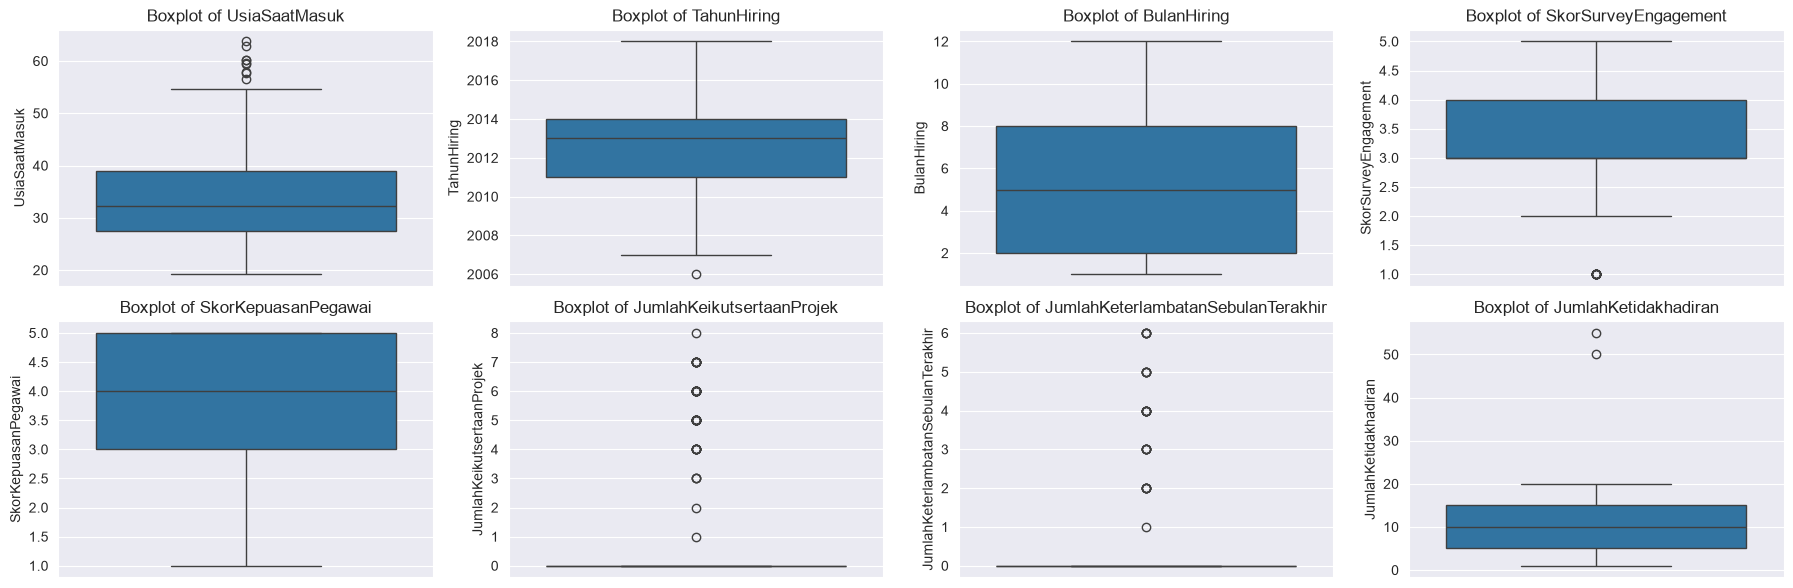

In [11]:
outlier_summary = filter_outliers(
    df,
    columns=schema.NUMERIC_COLUMNS,
    detect_only=True,
    verbose=False,
)
display(outlier_summary)

plot_dynamic_boxplots_violinplots(
    df,
    schema.NUMERIC_COLUMNS,
    plot_type="boxplot",
    ncols=4,
    figsize=(18, 6),
)


**Finding:** the count variables (`JumlahKeikutsertaanProjek`, `JumlahKeterlambatanSebulanTerakhir`, `JumlahKetidakhadiran`) are heavily zero-inflated and skewed. `UsiaSaatMasuk` is wide but plausible. The outliers are meaningful employee behaviour, not data-entry noise, so they are kept for modelling; tree-based models are robust to them and the linear model uses standardisation.


### Categorical Columns


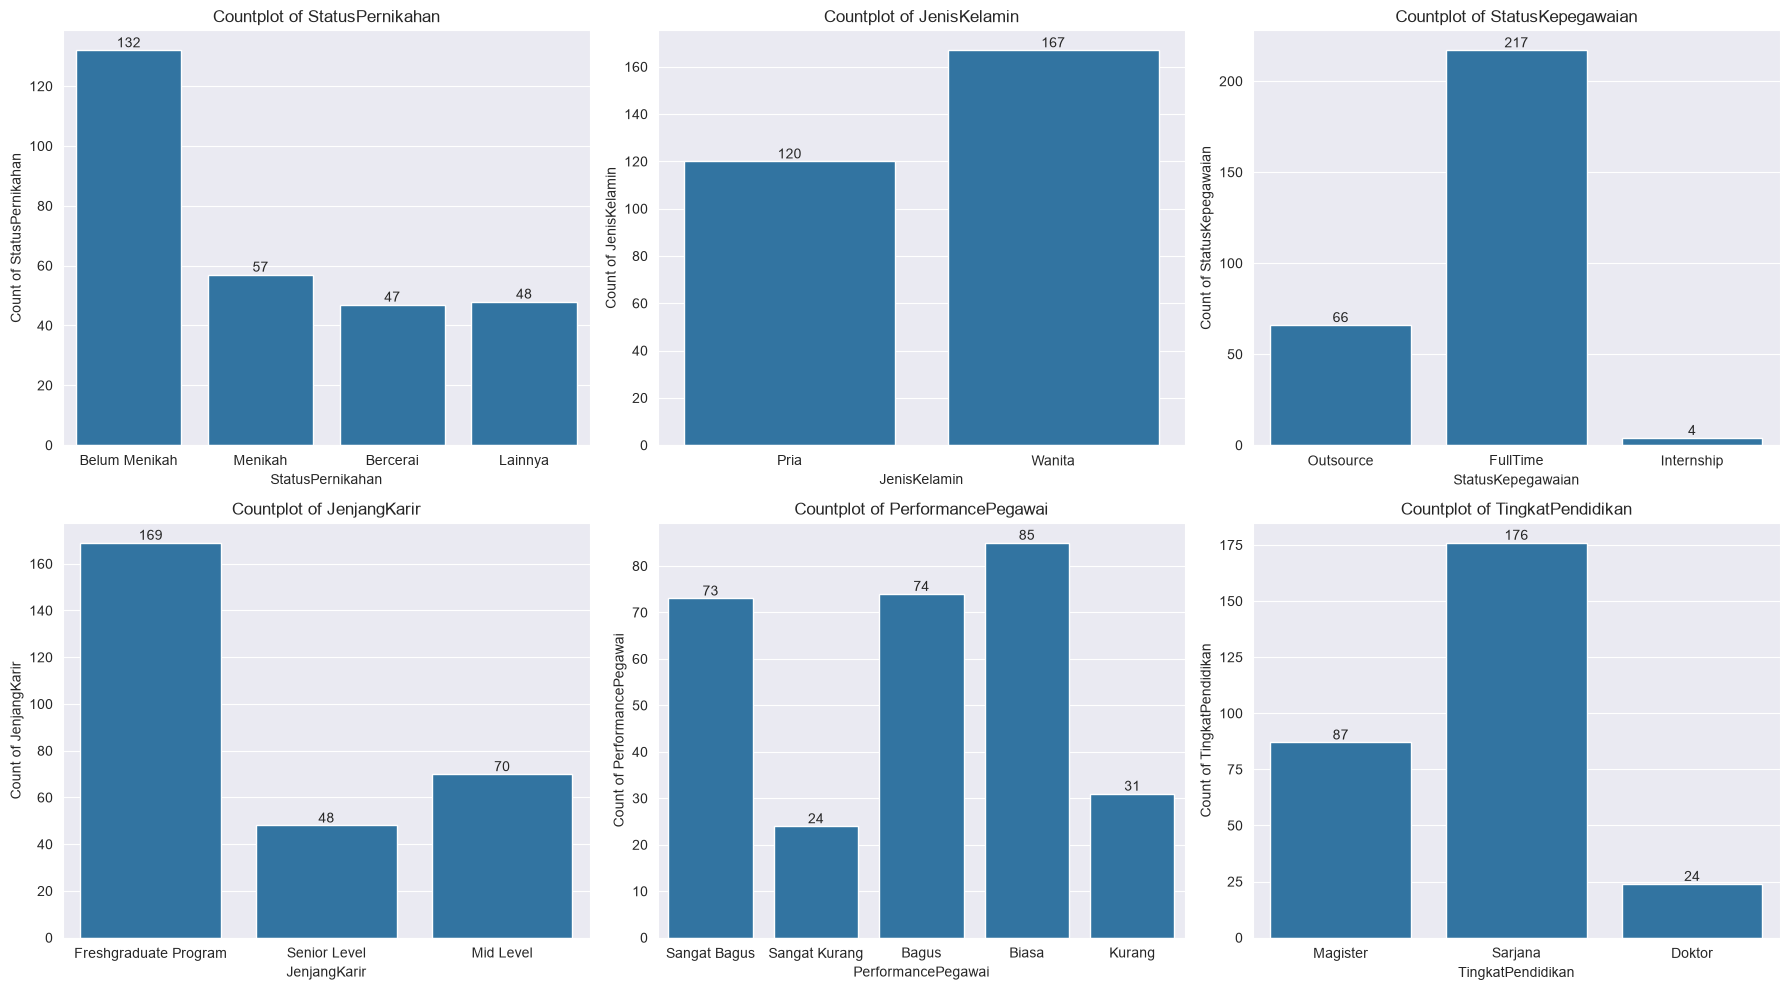

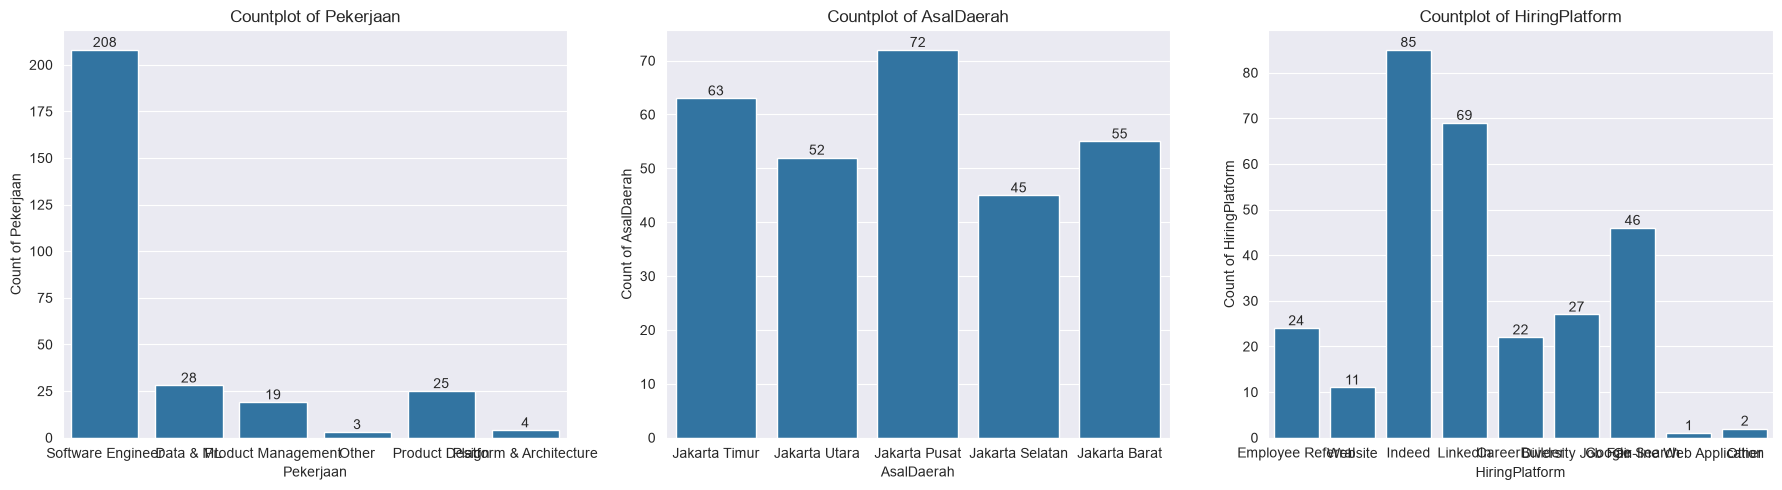

,Feature,overall_count,overall_unique,overall_top,overall_freq,overall_bottom,overall_freq_bottom,overall_top_percentage,overall_bottom_percentage,overall_n_categories
0,JenisKelamin,287,2,Wanita,167,Pria,120,58.19,41.81,2
1,JenjangKarir,287,3,Freshgraduate Program,169,Senior Level,48,58.89,16.72,3
2,PerformancePegawai,287,5,Biasa,85,Sangat Kurang,24,29.62,8.36,5
3,TingkatPendidikan,287,3,Sarjana,176,Doktor,24,61.32,8.36,3
4,StatusPernikahan,284,4,Belum Menikah,132,Bercerai,47,45.99,16.38,4
5,StatusKepegawaian,287,3,FullTime,217,Internship,4,75.61,1.39,3
6,Pekerjaan,287,6,Software Engineer,208,Other,3,72.47,1.05,6
7,AsalDaerah,287,5,Jakarta Pusat,72,Jakarta Selatan,45,25.09,15.68,5
8,HiringPlatform,287,9,Indeed,85,On-line Web Application,1,29.62,0.35,9


In [12]:
cats_few = [
    "StatusPernikahan",
    "JenisKelamin",
    "StatusKepegawaian",
    "JenjangKarir",
    "PerformancePegawai",
    "TingkatPendidikan",
]
cats_many = ["Pekerjaan", "AsalDaerah", "HiringPlatform"]

plot_dynamic_countplot(df=df, col_series=cats_few, ncols=3, figsize=(18, 10))
plot_dynamic_countplot(df=df, col_series=cats_many, ncols=3, figsize=(18, 5))
display(describe_categorical_combined(df, schema.RAW_CATEGORICAL_COLUMNS))


**Finding:** the workforce is dominated by full-time software engineers on the fresh-graduate track. `AsalDaerah` is entirely Jakarta, and the marital-status groups are reasonably balanced. Several job families have fewer than five employees, which is why they were grouped before encoding.


## Bivariate Analysis

### Numerical vs Target


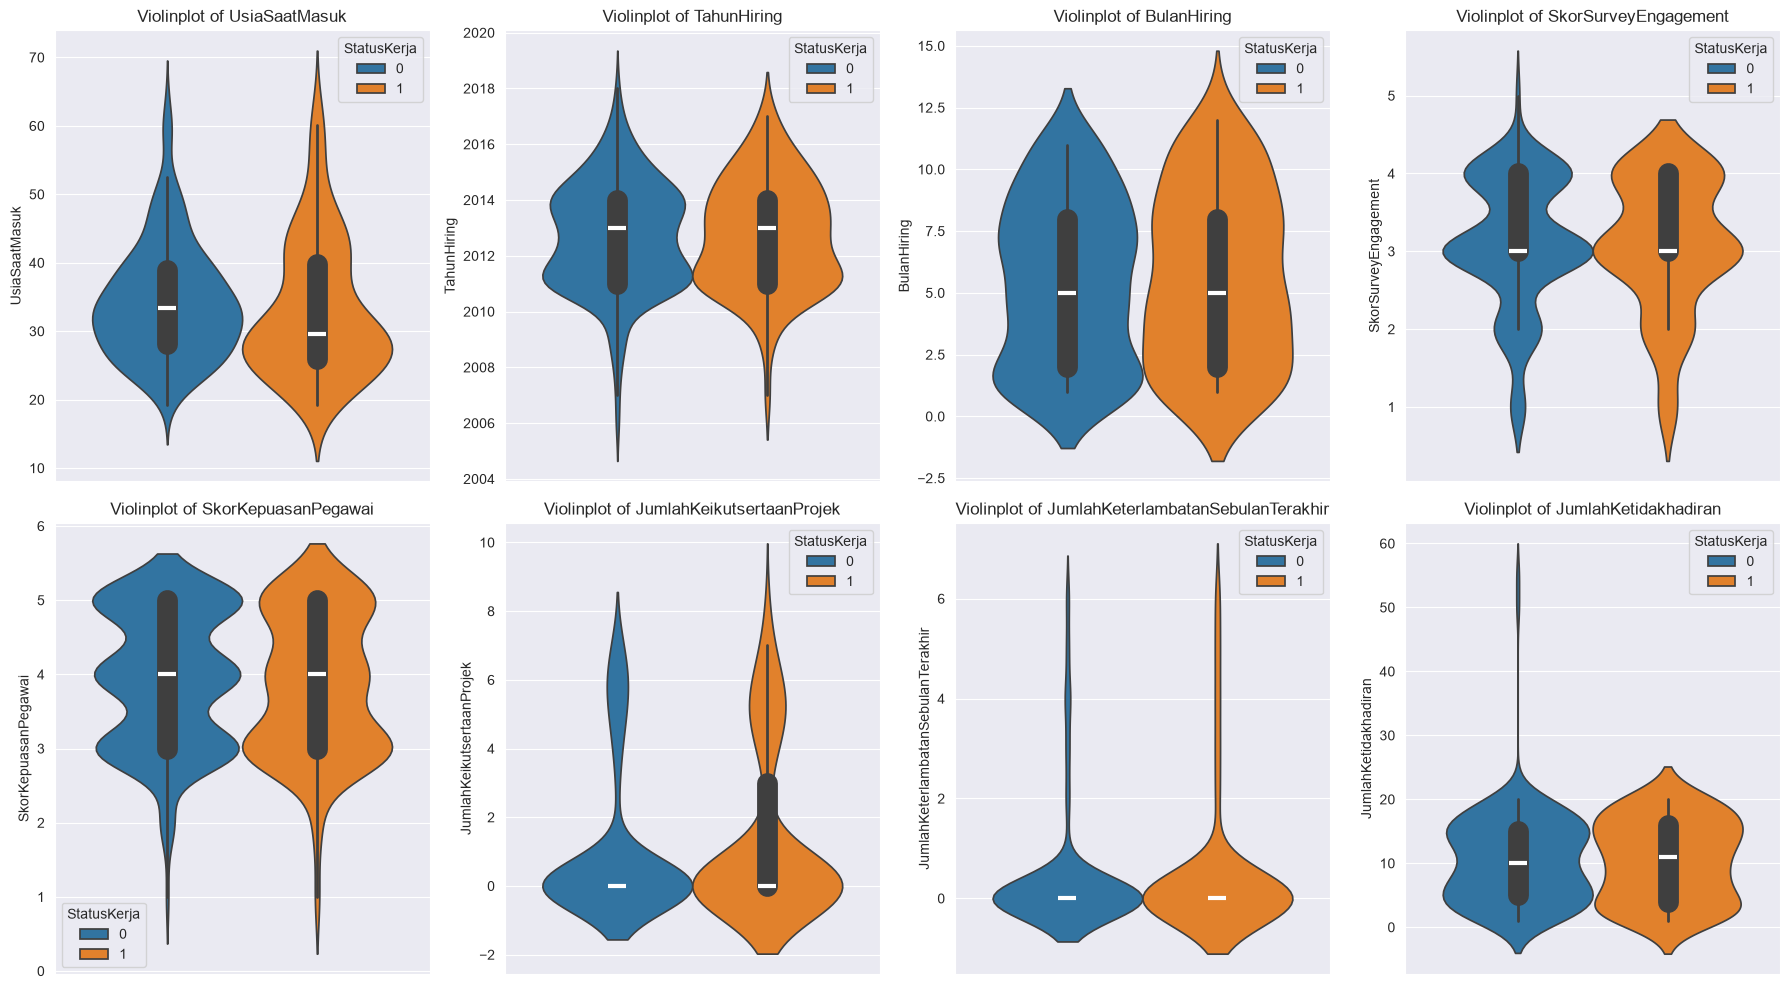

,Feature,overall_count,class_0_count,class_1_count,overall_mean,class_0_mean,class_1_mean,overall_std,class_0_std,class_1_std,overall_min,class_0_min,class_1_min,overall_25%,class_0_25%,class_1_25%,overall_50%,class_0_50%,class_1_50%,overall_75%,class_0_75%,class_1_75%,overall_max,class_0_max,class_1_max,overall_range,class_0_range,class_1_range,overall_IQR,class_0_IQR,class_1_IQR,overall_CV,class_0_CV,class_1_CV,overall_skewness,class_0_skewness,class_1_skewness,overall_kurtosis,class_0_kurtosis,class_1_kurtosis
0,UsiaSaatMasuk,287.0,198.0,89.0,33.976499,34.303487,33.249044,8.901529,8.354013,10.025558,19.22245,19.277207,19.22245,27.472964,28.185489,26.001369,32.238193,33.419576,29.620808,39.049966,38.871321,39.874059,63.739904,63.739904,62.811773,44.517454,44.462697,43.589322,11.577002,10.685832,13.87269,26.199077,24.353247,30.152921,0.916115,0.916826,0.967244,0.639025,0.885455,0.272052
1,TahunHiring,287.0,198.0,89.0,2012.689895,2012.676768,2012.719101,1.946308,1.950287,1.948127,2006.00000,2006.000000,2007.00000,2011.000000,2011.000000,2011.000000,2013.000000,2013.000000,2013.000000,2014.000000,2014.000000,2014.000000,2018.000000,2018.000000,2017.000000,12.000000,12.000000,10.000000,3.000000,3.000000,3.00000,0.096702,0.096900,0.096791,-0.092420,-0.141805,0.019189,0.096018,0.252400,-0.267722
2,BulanHiring,287.0,198.0,89.0,5.491289,5.434343,5.617978,3.329109,3.285599,3.439429,1.00000,1.000000,1.00000,2.000000,2.000000,2.000000,5.000000,5.000000,5.000000,8.000000,8.000000,8.000000,12.000000,11.000000,12.000000,11.000000,10.000000,11.000000,6.000000,6.000000,6.00000,60.625269,60.459904,61.221840,0.130550,0.107422,0.166848,-1.233714,-1.244383,-1.237559
3,SkorSurveyEngagement,287.0,198.0,89.0,3.101045,3.116162,3.067416,0.836388,0.831878,0.850104,1.00000,1.000000,1.00000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,4.000000,4.000000,3.000000,1.000000,1.000000,1.00000,26.971153,26.695613,27.714001,-0.622257,-0.590679,-0.686208,0.045287,0.099895,-0.090577
4,SkorKepuasanPegawai,282.0,194.0,88.0,3.904255,3.938144,3.829545,0.913355,0.902667,0.937367,1.00000,1.000000,1.00000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,4.000000,4.000000,2.000000,2.000000,2.00000,23.393825,22.921114,24.477244,-0.259309,-0.302096,-0.161044,-0.727294,-0.742255,-0.684234
5,JumlahKeikutsertaanProjek,284.0,195.0,89.0,1.179577,1.087179,1.382022,2.294441,2.235512,2.419173,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,8.000000,7.000000,8.000000,8.000000,7.000000,8.000000,0.000000,0.000000,3.00000,194.513772,205.624951,175.045887,1.548130,1.686232,1.285675,0.649091,1.078472,-0.066897
6,JumlahKeterlambatanSebulanTerakhir,286.0,197.0,89.0,0.412587,0.395939,0.449438,1.275016,1.239480,1.356895,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,0.000000,0.000000,0.00000,309.029279,313.048081,301.909171,3.110802,3.164558,2.989187,8.627340,9.023850,7.758262
7,JumlahKetidakhadiran,281.0,194.0,87.0,10.448399,10.474227,10.390805,6.902252,7.184602,6.266107,1.00000,1.000000,1.00000,5.000000,5.000000,4.000000,10.000000,10.000000,11.000000,15.000000,15.000000,16.000000,55.000000,55.000000,20.000000,54.000000,54.000000,19.000000,10.000000,10.000000,12.00000,66.060378,68.593147,60.304351,1.567496,2.016530,-0.003998,7.999739,10.166241,-1.361012


In [13]:
plot_dynamic_boxplots_violinplots(
    df,
    schema.NUMERIC_COLUMNS,
    plot_type="violinplot",
    ncols=4,
    figsize=(18, 10),
    hue=schema.TARGET_COLUMN,
)
display(
    describe_numerical_combined(
        df, schema.NUMERIC_COLUMNS, hue=schema.TARGET_COLUMN
    )
)


### Categorical vs Target


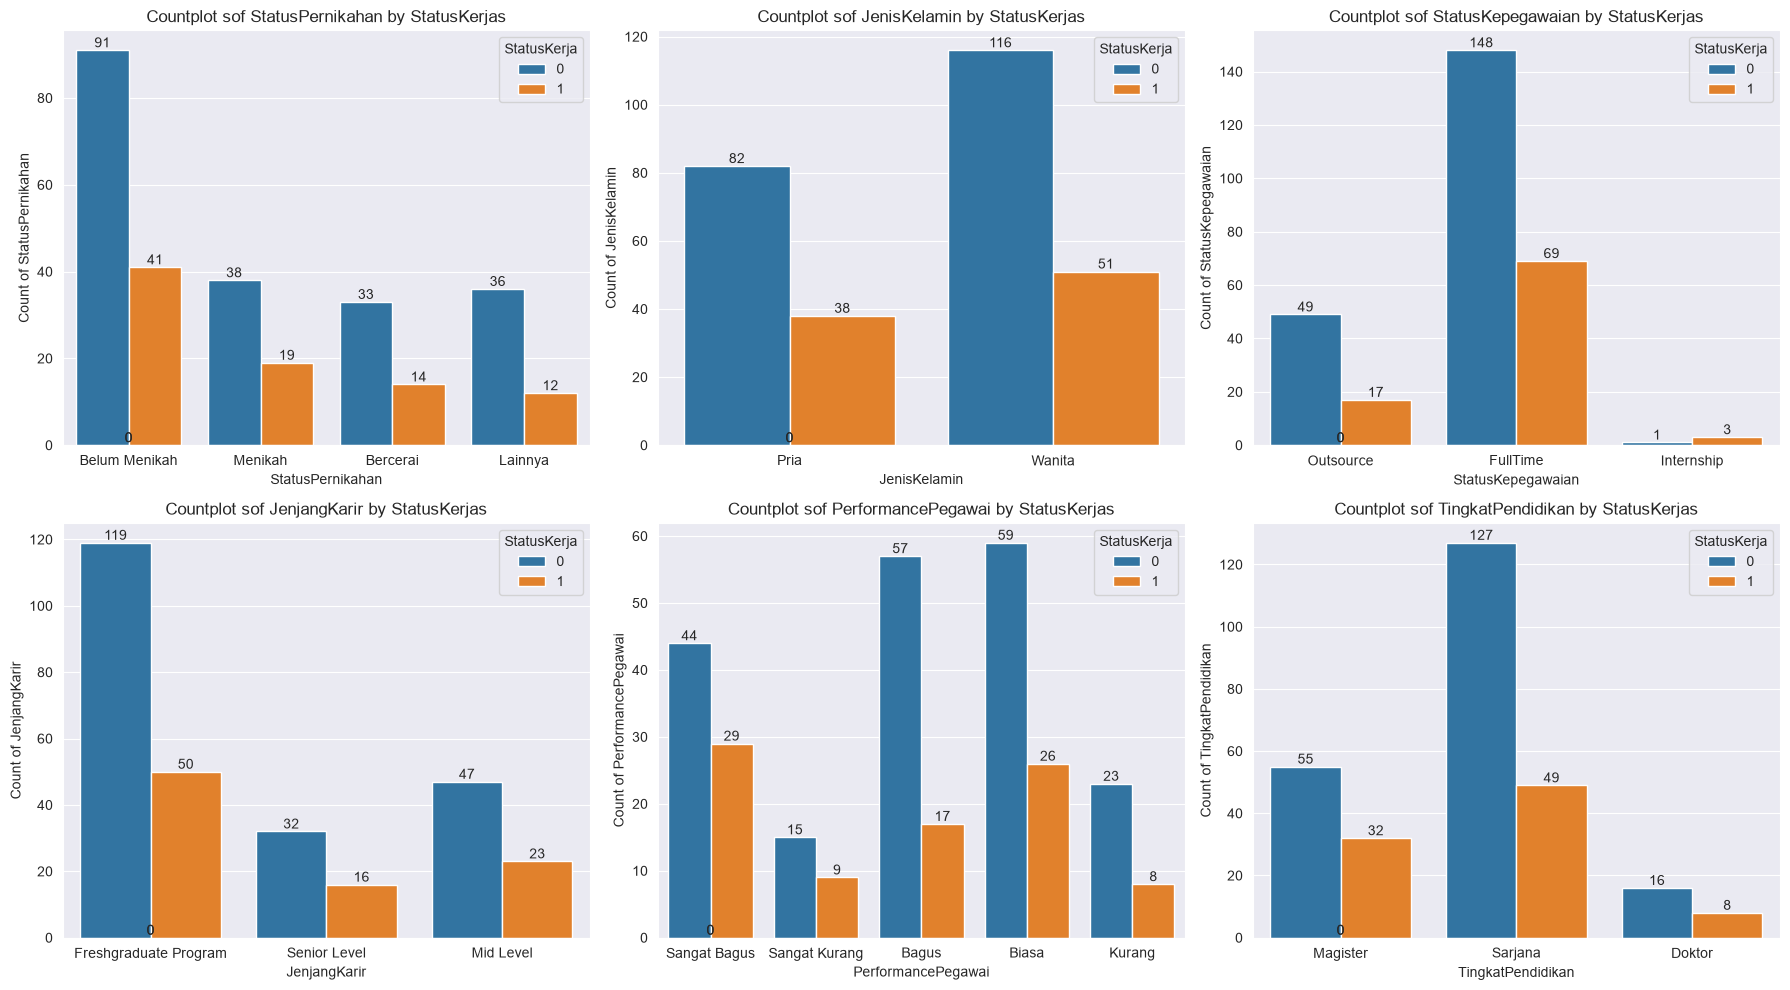

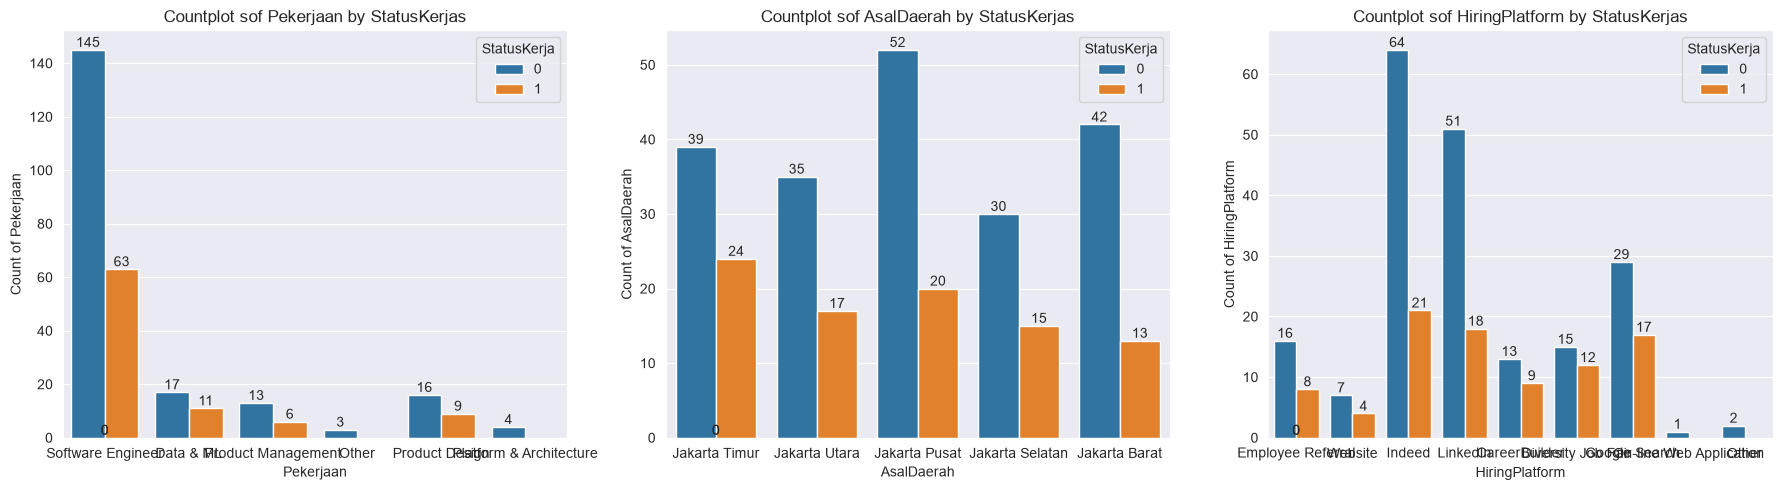

In [14]:
plot_dynamic_countplot(
    df=df,
    col_series=cats_few,
    ncols=3,
    figsize=(18, 10),
    hue=schema.TARGET_COLUMN,
)
plot_dynamic_countplot(
    df=df,
    col_series=cats_many,
    ncols=3,
    figsize=(18, 5),
    hue=schema.TARGET_COLUMN,
)


In [15]:
for column in ["JenjangKarir", "PerformancePegawai", "Pekerjaan", "HiringPlatform"]:
    print(f"=== {column} ===")
    display(attrition_by_group(df, column))


=== JenjangKarir ===


,JenjangKarir,employees,leavers,attrition_rate
0,Senior Level,48,16,0.333333
1,Mid Level,70,23,0.328571
2,Freshgraduate Program,169,50,0.295858


=== PerformancePegawai ===


,PerformancePegawai,employees,leavers,attrition_rate
0,Sangat Bagus,73,29,0.397260
1,Sangat Kurang,24,9,0.375000
2,Biasa,85,26,0.305882
3,Kurang,31,8,0.258065
4,Bagus,74,17,0.229730


=== Pekerjaan ===


,Pekerjaan,employees,leavers,attrition_rate
0,Data & ML,28,11,0.392857
1,Product Design,25,9,0.360000
2,Product Management,19,6,0.315789
3,Software Engineer,208,63,0.302885
4,Other,3,0,0.000000
5,Platform & Architecture,4,0,0.000000


=== HiringPlatform ===


,HiringPlatform,employees,leavers,attrition_rate
0,Diversity Job Fair,27,12,0.444444
1,CareerBuilder,22,9,0.409091
2,Google Search,46,17,0.369565
3,Website,11,4,0.363636
4,Employee Referral,24,8,0.333333
5,LinkedIn,69,18,0.260870
6,Indeed,85,21,0.247059
7,On-line Web Application,1,0,0.000000
8,Other,2,0,0.000000


,TahunHiring,employees,leavers,attrition_rate
0,2007,2,1,0.500000
1,2017,5,2,0.400000
2,2010,8,3,0.375000
3,2016,14,5,0.357143
4,2015,31,11,0.354839
5,2013,43,15,0.348837
6,2011,76,25,0.328947
7,2009,7,2,0.285714
8,2012,41,11,0.268293
9,2014,56,14,0.250000


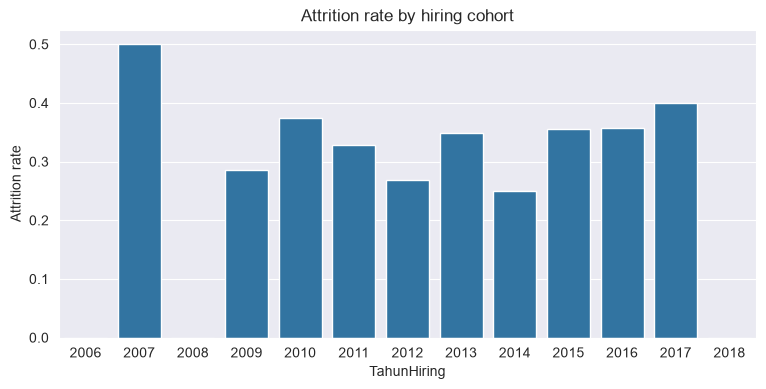

In [16]:
cohort = attrition_by_group(df, "TahunHiring")
display(cohort)

plt.figure(figsize=(9, 4))
sns.barplot(data=cohort, x="TahunHiring", y="attrition_rate")
plt.title("Attrition rate by hiring cohort")
plt.ylabel("Attrition rate")
plt.show()


**Findings (bivariate):**

- Attrition stays in a narrow band (roughly **23%–40%**) across career level, performance rating, and most job families; no single category separates leavers from stayers.
- Small groups can look dramatic: `Data Analyst` shows 50% attrition (8/16) and `Internship` shows 75% (3/4), but the sample is too small to act on those numbers alone.
- Engagement and satisfaction scores are almost flat between the two classes; absence and project counts move only slightly.
- The hiring cohort shows more variation than the profile fields, but year is partly a proxy for how long the employee has been exposed to the risk of leaving.

The weak separation is a property of the dataset, not a modelling failure. It is the main reason the final recommendation is to use the model as a **ranking aid**, not a hard verdict.


## Multivariate Analysis

### Correlation (Spearman)


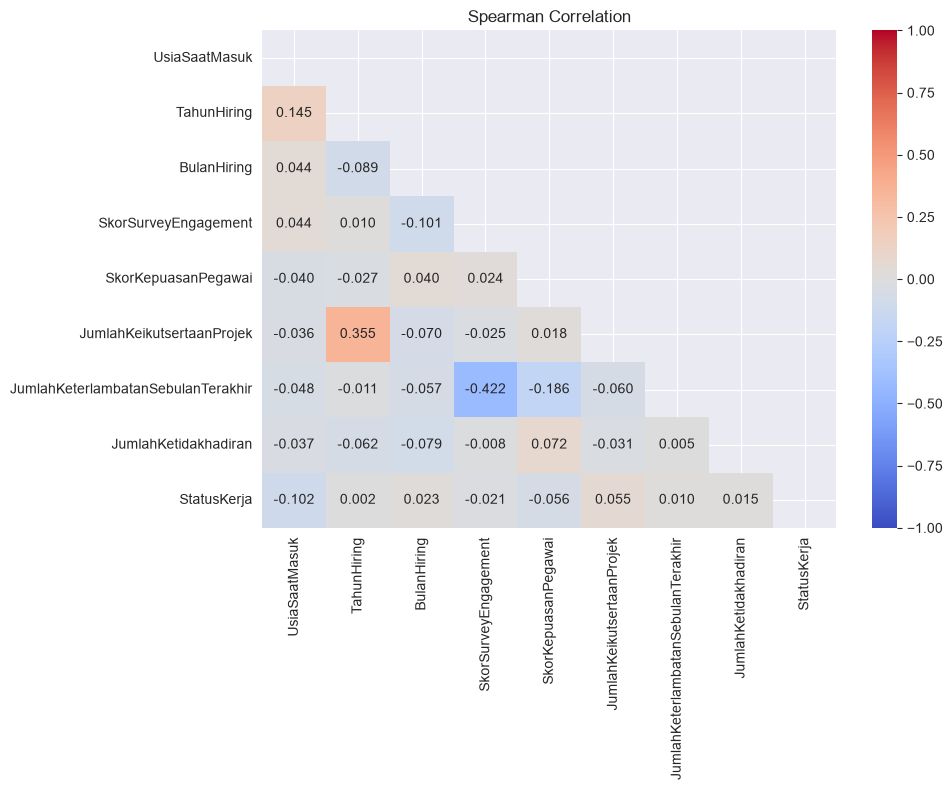

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,JumlahKeterlambatanSebulanTerakhir,SkorSurveyEngagement,0.422068,Negative
1,JumlahKeikutsertaanProjek,TahunHiring,0.355162,Positive
2,JumlahKeterlambatanSebulanTerakhir,SkorKepuasanPegawai,0.186494,Negative
3,TahunHiring,UsiaSaatMasuk,0.145470,Positive
4,BulanHiring,SkorSurveyEngagement,0.101340,Negative
5,BulanHiring,TahunHiring,0.088663,Negative
6,BulanHiring,JumlahKetidakhadiran,0.078536,Negative
7,JumlahKetidakhadiran,SkorKepuasanPegawai,0.071643,Positive
8,BulanHiring,JumlahKeikutsertaanProjek,0.069749,Negative
9,JumlahKetidakhadiran,TahunHiring,0.061741,Negative



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,UsiaSaatMasuk,0.102336,Negative
1,SkorKepuasanPegawai,0.055907,Negative
2,JumlahKeikutsertaanProjek,0.055299,Positive
3,BulanHiring,0.022896,Positive
4,SkorSurveyEngagement,0.020519,Negative
5,JumlahKetidakhadiran,0.015348,Positive
6,JumlahKeterlambatanSebulanTerakhir,0.010426,Positive
7,TahunHiring,0.001850,Positive


,Feature,Corr Value,Corr Type
0,UsiaSaatMasuk,0.102336,Negative
1,SkorKepuasanPegawai,0.055907,Negative
2,JumlahKeikutsertaanProjek,0.055299,Positive
3,BulanHiring,0.022896,Positive
4,SkorSurveyEngagement,0.020519,Negative
5,JumlahKetidakhadiran,0.015348,Positive
6,JumlahKeterlambatanSebulanTerakhir,0.010426,Positive
7,TahunHiring,0.001850,Positive


,A,B,Corr Value,Corr Type
0,JumlahKeterlambatanSebulanTerakhir,SkorSurveyEngagement,0.422068,Negative
1,JumlahKeikutsertaanProjek,TahunHiring,0.355162,Positive
2,JumlahKeterlambatanSebulanTerakhir,SkorKepuasanPegawai,0.186494,Negative
3,TahunHiring,UsiaSaatMasuk,0.145470,Positive
4,BulanHiring,SkorSurveyEngagement,0.101340,Negative
5,BulanHiring,TahunHiring,0.088663,Negative
6,BulanHiring,JumlahKetidakhadiran,0.078536,Negative
7,JumlahKetidakhadiran,SkorKepuasanPegawai,0.071643,Positive
8,BulanHiring,JumlahKeikutsertaanProjek,0.069749,Negative
9,JumlahKetidakhadiran,TahunHiring,0.061741,Negative


In [17]:
numeric_plus_target = schema.NUMERIC_COLUMNS + [schema.TARGET_COLUMN]
plot_correlation_heatmap(
    df,
    numeric_plus_target,
    corr_method="spearman",
    figsize=(10, 8),
)

feature_feature, feature_target = calculate_correlation_tabular(
    df[numeric_plus_target],
    target_col=schema.TARGET_COLUMN,
    method="spearman",
    corr_type="both",
)
display(feature_target.head(10))
display(feature_feature.head(10))


### Categorical association (Cramér's V)



Chi-Square Analysis Results:
--------------------------------------------------------------------------------


,Feature,Chi-Square,P-Value,Cramér's V,Effect Size,Is Significant,Strongest Category,Association Direction
8,HiringPlatform,7.962788,0.437113,0.166568,Small,False,Diversity Job Fair,Positive
2,PerformancePegawai,5.698370,0.222835,0.140908,Small,False,Sangat Bagus,Positive
5,StatusKepegawaian,4.532010,0.103726,0.125662,Small,False,Internship,Positive
6,Pekerjaan,4.387185,0.495118,0.123638,Small,False,Platform & Architecture,Negative
7,AsalDaerah,3.409975,0.491698,0.109002,Small,False,Jakarta Timur,Positive
3,TingkatPendidikan,2.241397,0.326052,0.088373,Negligible,False,Magister,Positive
4,StatusPernikahan,0.929055,0.818411,0.057195,Negligible,False,Lainnya,Negative
1,JenjangKarir,0.392973,0.821613,0.037003,Negligible,False,Freshgraduate Program,Negative
0,JenisKelamin,0.005531,0.940713,0.004390,Negligible,False,Pria,Positive


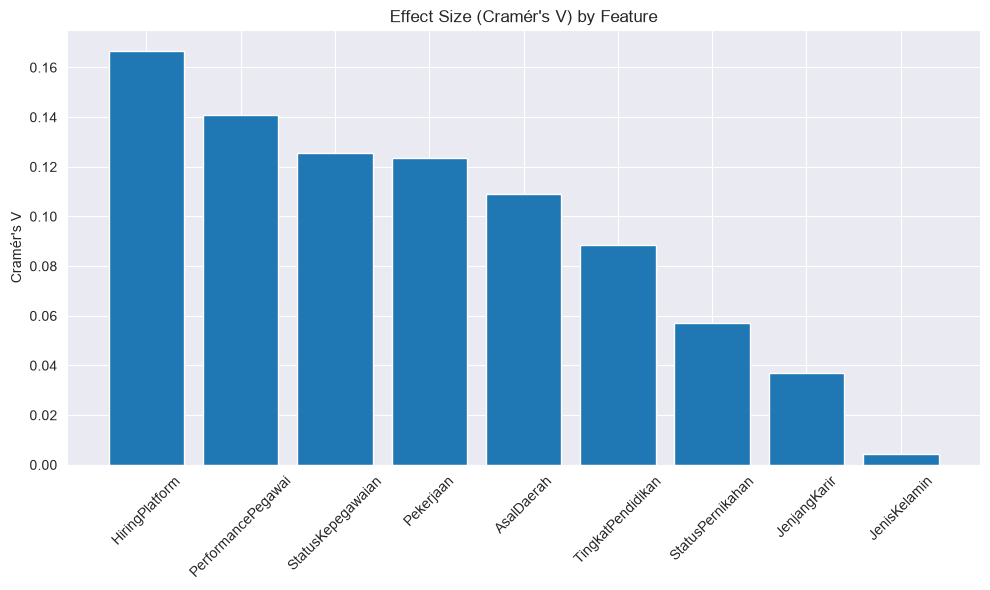

,Feature,Chi-Square,P-Value,Cramér's V,Effect Size,Is Significant,Strongest Category,Association Direction
8,HiringPlatform,7.962788,0.437113,0.166568,Small,False,Diversity Job Fair,Positive
2,PerformancePegawai,5.698370,0.222835,0.140908,Small,False,Sangat Bagus,Positive
5,StatusKepegawaian,4.532010,0.103726,0.125662,Small,False,Internship,Positive
6,Pekerjaan,4.387185,0.495118,0.123638,Small,False,Platform & Architecture,Negative
7,AsalDaerah,3.409975,0.491698,0.109002,Small,False,Jakarta Timur,Positive
3,TingkatPendidikan,2.241397,0.326052,0.088373,Negligible,False,Magister,Positive
4,StatusPernikahan,0.929055,0.818411,0.057195,Negligible,False,Lainnya,Negative
1,JenjangKarir,0.392973,0.821613,0.037003,Negligible,False,Freshgraduate Program,Negative
0,JenisKelamin,0.005531,0.940713,0.004390,Negligible,False,Pria,Positive


In [18]:
categorical_results = analyze_categorical_relationships(
    df,
    features=schema.RAW_CATEGORICAL_COLUMNS,
    target=schema.TARGET_COLUMN,
    alpha=0.05,
)
display(categorical_results)


**Finding:** no feature has a strong monotonic relationship with attrition. The largest correlations are modest, and the categorical associations are weak. This is consistent with the bivariate plots and sets the expectation for the modelling stage: the model can rank risk, but it will not separate leavers with high confidence.


# **STAGE 2 : DATA PREPROCESSING**

## Split, Impute, and Encode

The split happens **before** fitting imputation and encoding. Fitting on the full dataset would leak test-set category frequencies and medians into training.


In [19]:
X = df.drop(columns=[schema.TARGET_COLUMN])
y = df[schema.TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42,
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("Train target share:")
print(y_train.value_counts(normalize=True).round(3))
print("Test target share:")
print(y_test.value_counts(normalize=True).round(3))


Train: (200, 17) | Test: (87, 17)
Train target share:
StatusKerja
0    0.69
1    0.31
Name: proportion, dtype: float64
Test target share:
StatusKerja
0    0.69
1    0.31
Name: proportion, dtype: float64


In [20]:
imputation_values = fit_imputation_values(X_train)
X_train = apply_imputation_values(X_train, imputation_values)
X_test = apply_imputation_values(X_test, imputation_values)
imputation_values


{'StatusPernikahan': 'Belum Menikah',
 'SkorKepuasanPegawai': 4.0,
 'JumlahKeikutsertaanProjek': 0.0,
 'JumlahKeterlambatanSebulanTerakhir': 0.0,
 'JumlahKetidakhadiran': 11.0,
 'UsiaSaatMasuk': 32.573579739904176,
 'TahunHiring': 2013.0,
 'BulanHiring': 5.0}

In [21]:
X_train_enc, encoders = encode_features(X_train)
feature_columns = list(X_train_enc.columns)
X_test_enc, _ = encode_features(X_test, encoders=encoders)
X_test_enc = align_features(X_test_enc, feature_columns)

print(f"Encoded features: {len(feature_columns)}")
display(pd.DataFrame({"feature": feature_columns}))


Encoded features: 34


,feature
0,JenisKelamin
1,JenjangKarir
2,PerformancePegawai
3,TingkatPendidikan
4,StatusPernikahan_Bercerai
5,StatusPernikahan_Lainnya
6,StatusPernikahan_Menikah
7,StatusKepegawaian_Internship
8,StatusKepegawaian_Outsource
9,Pekerjaan_Other


## Feature Selection Diagnostics

VIF and univariate importance are used to understand the encoded space. The full set is retained for modelling: the signal is weak, dropping features would discard information, and L2 regularisation handles the correlated one-hot groups.


In [22]:
vif_frame = X_train_enc.assign(**{schema.TARGET_COLUMN: y_train.values})
vif_data = calculate_vif(
    vif_frame,
    target_col=schema.TARGET_COLUMN,
    high_threshold=10,
    moderate_threshold=5,
)
display(vif_data.head(10))
display(vif_data.tail(10))


,Feature,VIF,Interpretation
0,HiringPlatform_Indeed,3.893270,Low multicollinearity
1,HiringPlatform_LinkedIn,3.137939,Low multicollinearity
2,Pekerjaan_Software Engineer,2.782741,Low multicollinearity
3,HiringPlatform_Google Search,2.642438,Low multicollinearity
4,HiringPlatform_Diversity Job Fair,2.481203,Low multicollinearity
5,AsalDaerah_Jakarta Pusat,2.050269,Low multicollinearity
6,HiringPlatform_Employee Referral,1.938528,Low multicollinearity
7,Pekerjaan_Product Management,1.933399,Low multicollinearity
8,Pekerjaan_Product Design,1.899070,Low multicollinearity
9,AsalDaerah_Jakarta Timur,1.866100,Low multicollinearity


,Feature,VIF,Interpretation
24,Pekerjaan_Other,1.241274,Low multicollinearity
25,PerformancePegawai,1.225470,Low multicollinearity
26,HiringPlatform_Other,1.210236,Low multicollinearity
27,SkorKepuasanPegawai,1.205742,Low multicollinearity
28,BulanHiring,1.204686,Low multicollinearity
29,TingkatPendidikan,1.192120,Low multicollinearity
30,JenisKelamin,1.169227,Low multicollinearity
31,StatusKepegawaian_Internship,1.164329,Low multicollinearity
32,StatusKepegawaian_Outsource,1.161801,Low multicollinearity
33,JumlahKetidakhadiran,1.144488,Low multicollinearity


In [23]:
anova_importance = calculate_feature_importance(
    X_train_enc,
    y_train,
    task="classification",
    method="anova",
    k="all",
)
mutual_importance = calculate_feature_importance(
    X_train_enc,
    y_train,
    task="classification",
    method="mutual_info",
    k="all",
)
print("ANOVA F-test (top 15)")
display(anova_importance.head(15))
print("Mutual information (top 15)")
display(mutual_importance.head(15))


ANOVA F-test (top 15)


,Feature,Score,P_Values
7,StatusKepegawaian_Internship,4.554000,0.034072
22,HiringPlatform_LinkedIn,3.894565,0.049834
5,StatusPernikahan_Lainnya,3.051739,0.082201
18,HiringPlatform_Diversity Job Fair,2.816861,0.094856
30,SkorKepuasanPegawai,2.561988,0.111055
21,HiringPlatform_Indeed,2.523047,0.113789
16,AsalDaerah_Jakarta Timur,2.234539,0.136549
20,HiringPlatform_Google Search,2.051550,0.153628
10,Pekerjaan_Platform & Architecture,1.832239,0.177407
2,PerformancePegawai,1.811325,0.179888


Mutual information (top 15)


,Feature,Score,P_Values
32,JumlahKeterlambatanSebulanTerakhir,0.076019,None
26,UsiaSaatMasuk,0.066102,None
3,TingkatPendidikan,0.059575,None
4,StatusPernikahan_Bercerai,0.054661,None
7,StatusKepegawaian_Internship,0.044322,None
6,StatusPernikahan_Menikah,0.041235,None
14,AsalDaerah_Jakarta Pusat,0.037160,None
11,Pekerjaan_Product Design,0.032874,None
20,HiringPlatform_Google Search,0.020393,None
17,AsalDaerah_Jakarta Utara,0.017695,None


# **STAGE 3 : MODELLING AND EVALUATION**

## Evaluation Strategy

- **ROC-AUC** is the primary model-selection metric: it is threshold-free and insensitive to the 69/31 class balance.
- **PR-AUC (average precision)** and **recall** are reported because the positive class (leavers) is the one HR cares about.
- **Accuracy** is shown only next to the majority-class baseline; 69% accuracy is free.
- **Repeated stratified 5-fold CV (3 repeats)** gives a more stable estimate than a single split.
- **Cumulative gains** translate the scores into a capacity decision: if HR can follow up with the top 20%, how many leavers are captured?


## Majority-Class Baseline


In [24]:
dummy = DummyClassifier(strategy="prior", random_state=42)
dummy.fit(X_train_enc, y_train)
dummy_metrics = eval_classification(
    model=dummy,
    X_train=X_train_enc,
    y_train=y_train,
    X_test=X_test_enc,
    y_test=y_test,
    plot_confusion_matrix=False,
    plot_roc_curve=False,
    plot_pr_curve=False,
    plot_calibration_curve=False,
    plot_threshold_analysis=False,
    display=False,
)
print(f"Baseline accuracy: {dummy_metrics['accuracy']['test']:.3f}")
print(f"Baseline recall:   {dummy_metrics['recall']['test']:.3f}")
print(f"Baseline ROC-AUC:  {dummy_metrics['roc_auc']['test']:.3f}")


Baseline accuracy: 0.690
Baseline recall:   0.000
Baseline ROC-AUC:  0.500


The baseline confirms the metric choice: it scores about 0.69 accuracy while catching **zero** leavers. Any model that claims to help must beat it on recall and ranking, not on accuracy.


## Train Vanilla Models


In [25]:
vanilla_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
}

for model in vanilla_models.values():
    model.fit(X_train_enc, y_train)


In [26]:
vanilla_metrics = {}
for name, model in vanilla_models.items():
    vanilla_metrics[name] = eval_classification(
        model=model,
        X_train=X_train_enc,
        y_train=y_train,
        X_test=X_test_enc,
        y_test=y_test,
        plot_confusion_matrix=False,
        plot_roc_curve=False,
        plot_pr_curve=False,
        plot_calibration_curve=False,
        plot_threshold_analysis=False,
        display=False,
    )

vanilla_comparison = compare_cv_metrics(vanilla_metrics, as_numeric=True)
display(vanilla_comparison)


,Model,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
0,Logistic Regression,0.615000,0.261231,0.150855,0.184792,0.543581
1,K-Nearest Neighbors,0.660000,0.416306,0.223504,0.287129,0.611739
2,Decision Tree,0.598333,0.360518,0.391880,0.371128,0.541399
3,Random Forest,0.691667,0.484444,0.075214,0.125812,0.588883
4,Gradient Boosting,0.646667,0.408941,0.288889,0.327971,0.574013
5,XGBoost,0.665000,0.437914,0.329060,0.367745,0.622819


**Finding (vanilla models, repeated 5-fold CV):**

- XGBoost reaches the best vanilla CV ROC-AUC (**0.623**), followed by K-Nearest Neighbors (**0.612**), while Logistic Regression sits at **0.544** and the single Decision Tree at **0.541**.
- Random Forest has high accuracy (**0.692**) but recall of only **0.075** — it catches almost no leavers. This is the accuracy trap in action.
- The trees fit the training data much better than the test data, which is expected with 200 training rows and 34 encoded features. Hyperparameter tuning is needed to constrain model complexity.


## Hyperparameter Tuning

Each model is wrapped in a `StandardScaler` pipeline so scaling is fitted inside every CV fold. Random search keeps the runtime manageable on a small Windows machine.


In [27]:
MODEL_KEYS = [
    "logisticregression",
    "knn",
    "decisiontree",
    "randomforest",
    "gb",
    "xgboost",
]
DISPLAY_NAMES = {
    "logisticregression": "Logistic Regression",
    "knn": "K-Nearest Neighbors",
    "decisiontree": "Decision Tree",
    "randomforest": "Random Forest",
    "gb": "Gradient Boosting",
    "xgboost": "XGBoost",
}


def scaled_pipeline(key):
    base = get_model_pipeline(key, random_state=42)
    return Pipeline([("scaler", StandardScaler()), *base.steps])


pipelines = {key: scaled_pipeline(key) for key in MODEL_KEYS}
param_grid = {
    key: get_hyperparameters(key, search_method="random")
    for key in MODEL_KEYS
}

tuned_searches, fit_times = tune_pipelines(
    pipedict=pipelines,
    param_grid=param_grid,
    X_train=X_train_enc,
    y_train=y_train,
    X_test=X_test_enc,
    y_test=y_test,
    scoring="roc_auc",
    search_method="random",
    n_iter=20,
    n_splits=5,
    n_repeats=3,
    random_state=42,
    display=False,
    plot_learning_curves=False,
    n_jobs=1,
)

tuned_models = {
    DISPLAY_NAMES[key]: search.best_estimator_
    for key, search in tuned_searches.items()
}
tuning_table = pd.DataFrame(
    {
        "Model": [DISPLAY_NAMES[key] for key in MODEL_KEYS],
        "Best CV ROC-AUC": [tuned_searches[key].best_score_ for key in MODEL_KEYS],
        "Holdout ROC-AUC": [tuned_searches[key].test_score_ for key in MODEL_KEYS],
        "Fit seconds": fit_times,
    }
)
display(tuning_table.sort_values("Best CV ROC-AUC", ascending=False))


,Model,Best CV ROC-AUC,Holdout ROC-AUC,Fit seconds
2,Decision Tree,0.661215,0.543519,8.51
5,XGBoost,0.641226,0.553704,52.36
4,Gradient Boosting,0.632730,0.524691,54.65
3,Random Forest,0.623333,0.427160,91.93
0,Logistic Regression,0.578880,0.477160,10.25
1,K-Nearest Neighbors,0.573793,0.503395,11.73


In [28]:
tuned_metrics = {}
for name, model in tuned_models.items():
    tuned_metrics[name] = eval_classification(
        model=model,
        X_train=X_train_enc,
        y_train=y_train,
        X_test=X_test_enc,
        y_test=y_test,
        plot_confusion_matrix=False,
        plot_roc_curve=False,
        plot_pr_curve=False,
        plot_calibration_curve=False,
        plot_threshold_analysis=False,
        display=False,
    )

tuned_comparison = compare_cv_metrics(tuned_metrics, as_numeric=True)
display(tuned_comparison.sort_values("ROC_AUC", ascending=False))


,Model,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
2,Decision Tree,0.690000,0.476667,0.216239,0.291315,0.661215
5,XGBoost,0.688333,0.524921,0.166667,0.243477,0.641226
4,Gradient Boosting,0.653333,0.432671,0.360684,0.384852,0.632730
3,Random Forest,0.681667,0.033333,0.005556,0.009524,0.623333
0,Logistic Regression,0.620000,0.344645,0.258120,0.284461,0.578880
1,K-Nearest Neighbors,0.658333,0.336111,0.097009,0.142431,0.573793


## Model Selection

The selection rule is: take the highest CV ROC-AUC, but prefer **Logistic Regression** when it is within **0.02 ROC-AUC** of the winner. On a 287-row dataset the difference between the top models is usually within noise, and the linear model gives exact per-employee contributions for the app.

**Result:** Decision Tree wins the tuned comparison at **0.661 CV ROC-AUC**. Logistic Regression scores **0.579**, a gap of **0.082**, so the 0.02 tolerance does not apply and the Decision Tree is deployed. The app therefore falls back to global permutation importance instead of per-employee coefficients.


In [29]:
selection = tuned_comparison.set_index("Model")
best_name = selection["ROC_AUC"].idxmax()
lr_score = selection.loc["Logistic Regression", "ROC_AUC"]

if (
    best_name != "Logistic Regression"
    and selection.loc[best_name, "ROC_AUC"] - lr_score <= 0.02
):
    selected_name = "Logistic Regression"
else:
    selected_name = best_name

selected_model = tuned_models[selected_name]

print(f"Best CV model: {best_name} ({selection.loc[best_name, 'ROC_AUC']:.3f})")
print(f"Deployed model: {selected_name}")
display(selection.sort_values("ROC_AUC", ascending=False))


Best CV model: Decision Tree (0.661)
Deployed model: Decision Tree


,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
Model,,,,,
Decision Tree,0.690000,0.476667,0.216239,0.291315,0.661215
XGBoost,0.688333,0.524921,0.166667,0.243477,0.641226
Gradient Boosting,0.653333,0.432671,0.360684,0.384852,0.632730
Random Forest,0.681667,0.033333,0.005556,0.009524,0.623333
Logistic Regression,0.620000,0.344645,0.258120,0.284461,0.578880
K-Nearest Neighbors,0.658333,0.336111,0.097009,0.142431,0.573793


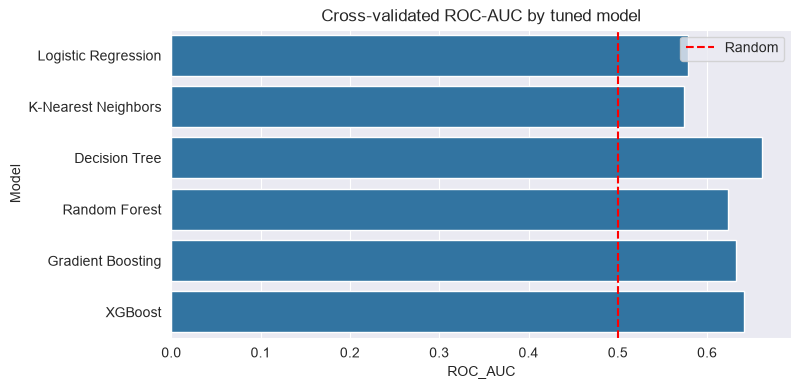

In [30]:
plt.figure(figsize=(8, 4))
sns.barplot(data=tuned_comparison, x="ROC_AUC", y="Model")
plt.axvline(0.5, color="red", linestyle="--", label="Random")
plt.title("Cross-validated ROC-AUC by tuned model")
plt.legend()
plt.show()


**Finding (tuned models, repeated 5-fold CV):**

| Model | CV ROC-AUC | Holdout ROC-AUC |
|---|---:|---:|
| Decision Tree | **0.661** | 0.544 |
| XGBoost | 0.641 | 0.554 |
| Gradient Boosting | 0.633 | 0.525 |
| Random Forest | 0.623 | 0.427 |
| Logistic Regression | 0.579 | 0.477 |
| K-Nearest Neighbors | 0.574 | 0.503 |

The CV ranking and the single holdout ranking disagree, which is a warning that the differences are within noise on 87 test rows. The tuned Decision Tree is far from a strong classifier; the 0.661 CV estimate and 0.544 holdout estimate bracket a wide uncertainty range. The notebook keeps the CV-based selection rule for reproducibility, but the honest conclusion is that these features do not support high-confidence prediction.


## Selected Model Analysis


Performance Metrics for Pipeline:



Cross-Validated Metrics (mean ± std):



ACCURACY:


  Test:  69.00 ± 3.27


  Train: 72.46 ± 0.70



PRECISION:


... (23 outputs left out)

  Train: 51.79



ROC_AUC:


  Test:  54.35


  Train: 76.17


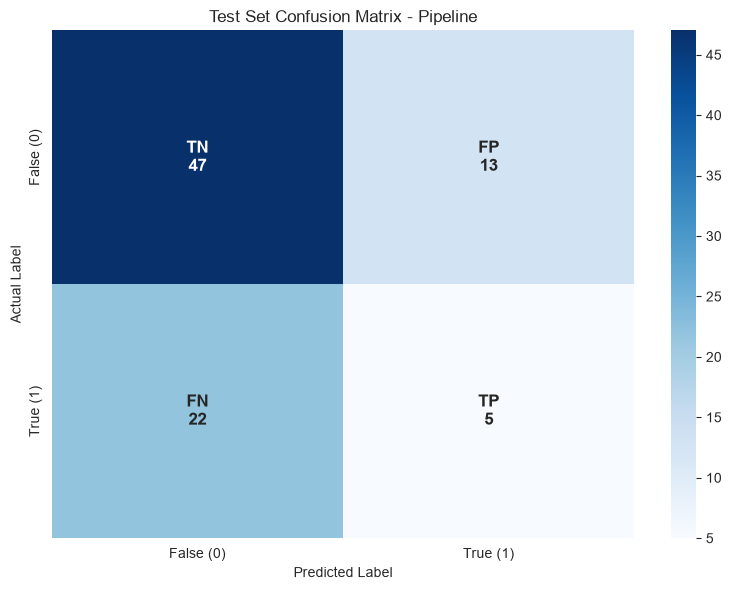

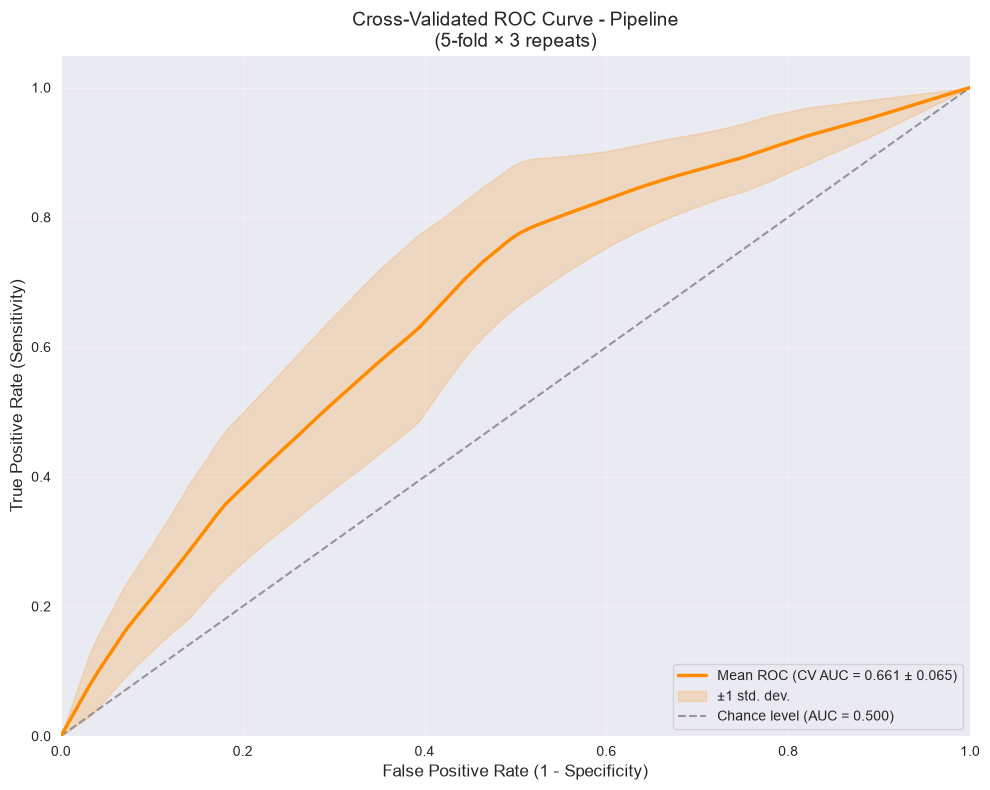

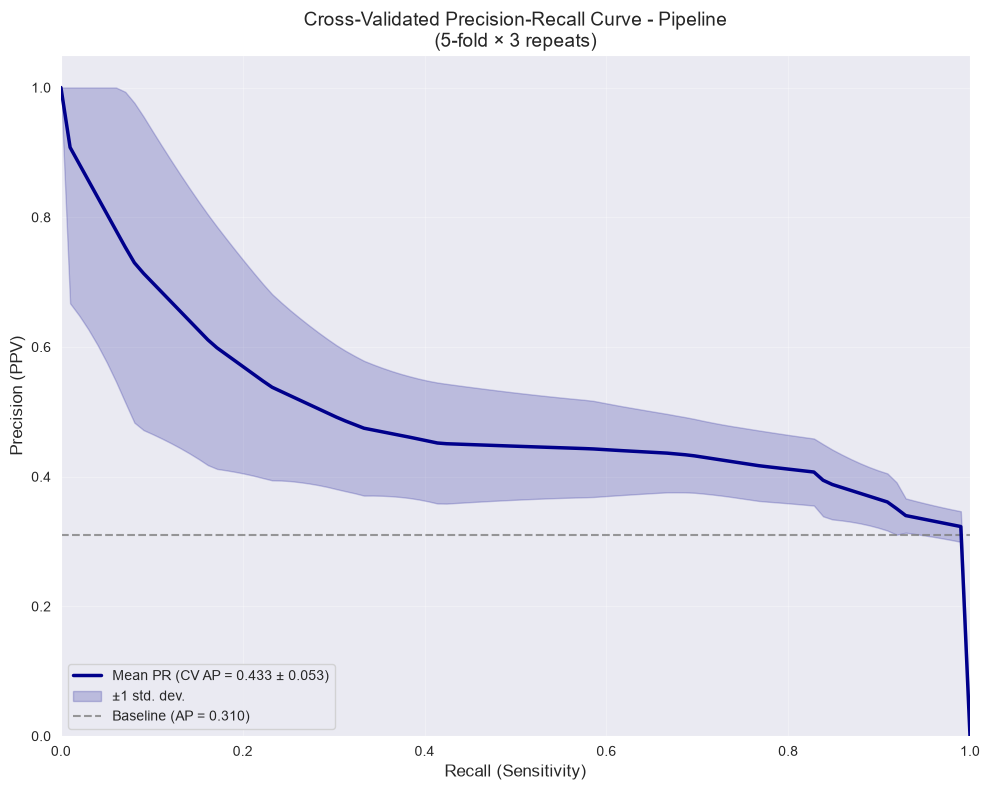

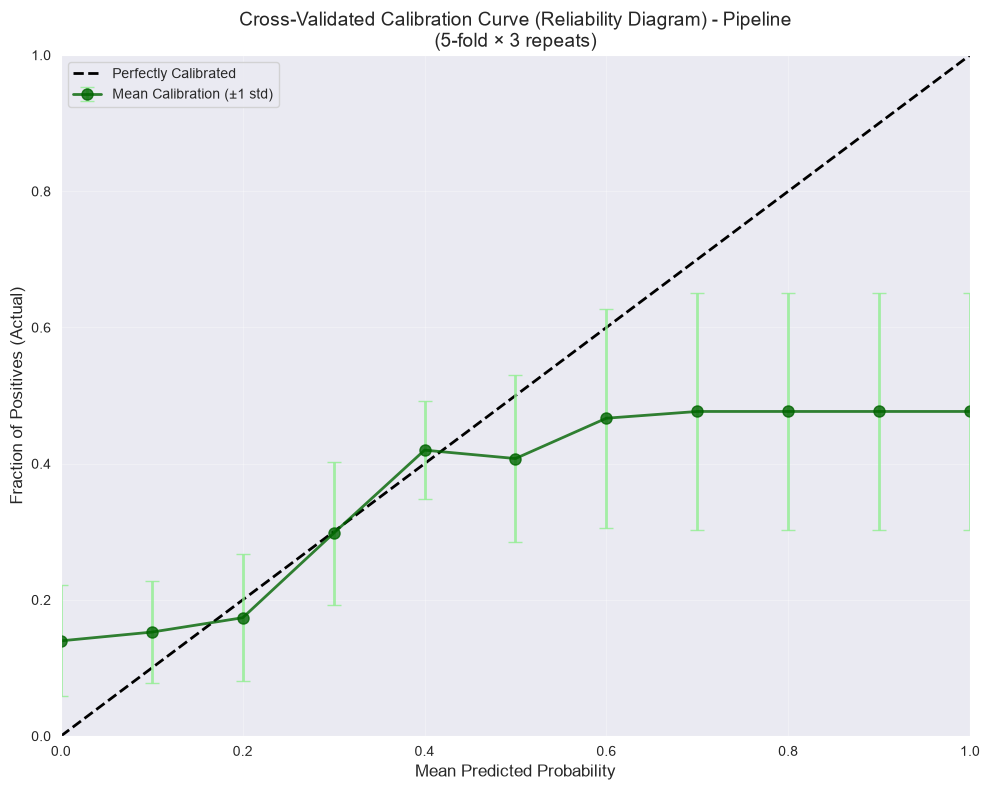

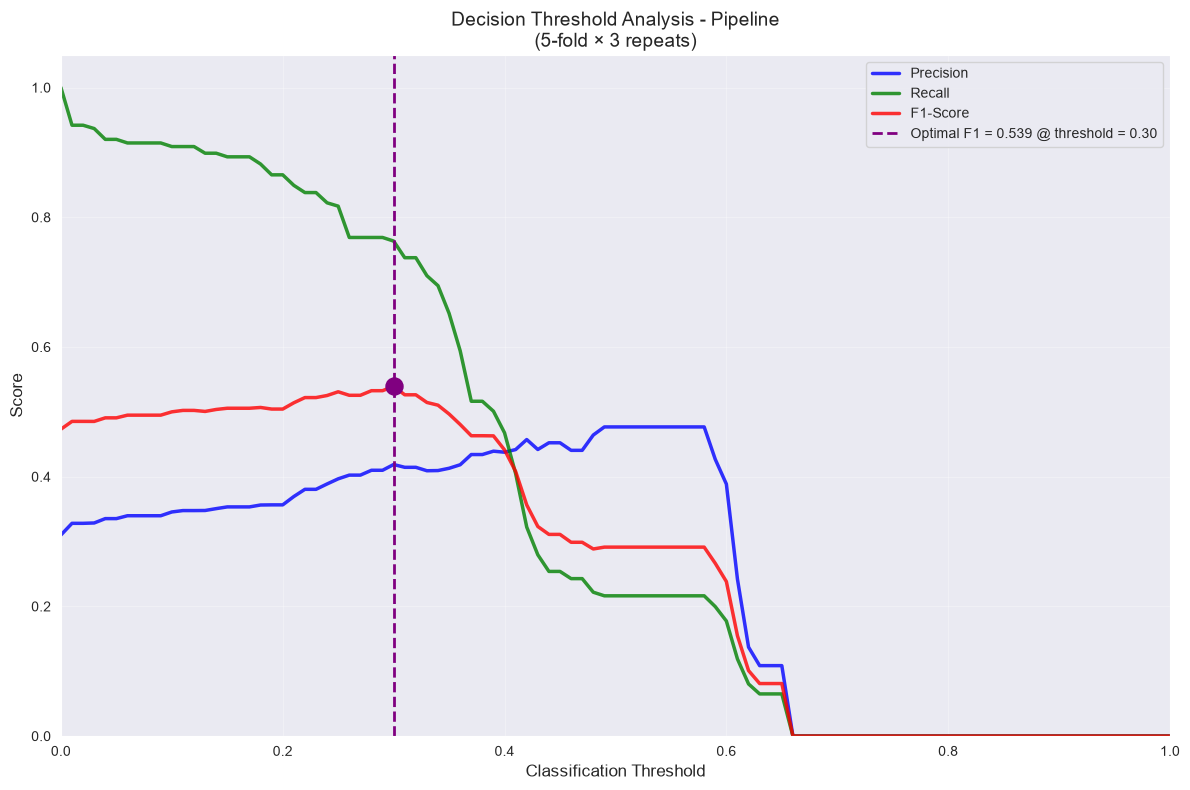

In [31]:
final_metrics = eval_classification(
    model=selected_model,
    X_train=X_train_enc,
    y_train=y_train,
    X_test=X_test_enc,
    y_test=y_test,
)


In [32]:
y_pred = selected_model.predict(X_test_enc)
y_proba = selected_model.predict_proba(X_test_enc)[:, 1]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[schema.TARGET_LABELS[0], schema.TARGET_LABELS[1]],
        digits=3,
    )
)


               precision    recall  f1-score   support

Masih Bekerja      0.681     0.783     0.729        60
Tidak Bekerja      0.278     0.185     0.222        27

     accuracy                          0.598        87
    macro avg      0.479     0.484     0.475        87
 weighted avg      0.556     0.598     0.572        87



In [33]:
metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1": float(f1_score(y_test, y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, y_proba)),
    "average_precision": float(average_precision_score(y_test, y_proba)),
    "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    "threshold": 0.5,
}
display(pd.DataFrame([metrics]).drop(columns=["confusion_matrix"]))
print("Confusion matrix:", metrics["confusion_matrix"])


,accuracy,precision,recall,f1,roc_auc,average_precision,threshold
0,0.597701,0.277778,0.185185,0.222222,0.543519,0.335235,0.5


Confusion matrix: [[47, 13], [22, 5]]


**Held-out test results at 0.5:** accuracy **0.598**, precision **0.278**, recall **0.185**, F1 **0.222**, ROC-AUC **0.544**, PR-AUC **0.335**, confusion matrix `[[47, 13], [22, 5]]`.

Only **5 of 27** actual leavers are caught, while 13 stayers are flagged. The model is conservative and misses most of the people HR cares about. This is exactly why the app reports a probability and a risk tier rather than a yes/no verdict, and why the gains curve is the business-relevant view.


## Feature Importance

### Permutation Importance


In [34]:
perm = permutation_importance(
    selected_model,
    X_test_enc,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
)
permutation_df = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    }
).sort_values("importance_mean", ascending=False)
display(permutation_df.head(15))


,feature,importance_mean,importance_std
26,UsiaSaatMasuk,0.061914,0.053314
2,PerformancePegawai,0.010910,0.011882
1,JenjangKarir,0.000000,0.000000
0,JenisKelamin,0.000000,0.000000
4,StatusPernikahan_Bercerai,0.000000,0.000000
3,TingkatPendidikan,0.000000,0.000000
6,StatusPernikahan_Menikah,0.000000,0.000000
7,StatusKepegawaian_Internship,0.000000,0.000000
8,StatusKepegawaian_Outsource,0.000000,0.000000
5,StatusPernikahan_Lainnya,0.000000,0.000000


In [35]:
final_estimator = selected_model.steps[-1][1]
if hasattr(final_estimator, "coef_"):
    coefficients = pd.DataFrame(
        {
            "feature": feature_columns,
            "coefficient": final_estimator.coef_[0],
        }
    )
    coefficients["abs_coefficient"] = coefficients["coefficient"].abs()
    coefficients = coefficients.sort_values(
        "abs_coefficient", ascending=False
    )
    display(coefficients.head(15))

    top = coefficients.head(12).iloc[::-1]
    plt.figure(figsize=(8, 5))
    plt.barh(top["feature"], top["coefficient"])
    plt.title("Top logistic coefficients")
    plt.xlabel("Coefficient (log-odds per SD)")
    plt.show()
else:
    coefficients = None
    print("Selected model is non-linear; use permutation importance.")


Selected model is non-linear; use permutation importance.


**Interpretation:** because the deployed model is a **Decision Tree**, there is no coefficient table. Permutation importance is dominated by `UsiaSaatMasuk` (**0.062 ± 0.053 ROC-AUC**), with `PerformancePegawai` a distant second (**0.011 ± 0.012**); every other feature has zero measured importance. The tree is effectively splitting on age at hire, which is a fragile basis for an HR decision. Do not read this as evidence that age causes attrition; it is the only signal the tree found in this sample.


## Risk Tiers and Capacity Gains

The app uses **relative** risk tiers rather than a 0.5 cut: the top 20% of the training score distribution is "High", the next 30% is "Moderate", and the rest is "Low". This matches an HR team that can only follow up with a limited number of employees.


In [36]:
train_proba = selected_model.predict_proba(X_train_enc)[:, 1]
sorted_train_proba = np.sort(train_proba)
risk_tier_cutoffs = {
    "moderate": float(np.quantile(train_proba, 0.50)),
    "high": float(np.quantile(train_proba, 0.80)),
}
test_predictions = pd.DataFrame(
    {
        "y_true": y_test.to_numpy(),
        "y_proba": y_proba,
    }
)
test_predictions["risk_tier"] = [
    risk_tier(probability, risk_tier_cutoffs)
    for probability in test_predictions["y_proba"]
]

print("Risk tier cutoffs:", risk_tier_cutoffs)
display(test_predictions["risk_tier"].value_counts())


Risk tier cutoffs: {'moderate': 0.25, 'high': 0.55}


risk_tier
Low         40
Moderate    29
High        18
Name: count, dtype: int64

,targeted_share,employees_targeted,leavers_captured,captured_share,lift
0,0.1,9,3,0.111111,1.111111
1,0.2,18,5,0.185185,0.925926
2,0.3,27,10,0.370370,1.234568
3,0.5,44,16,0.592593,1.185185


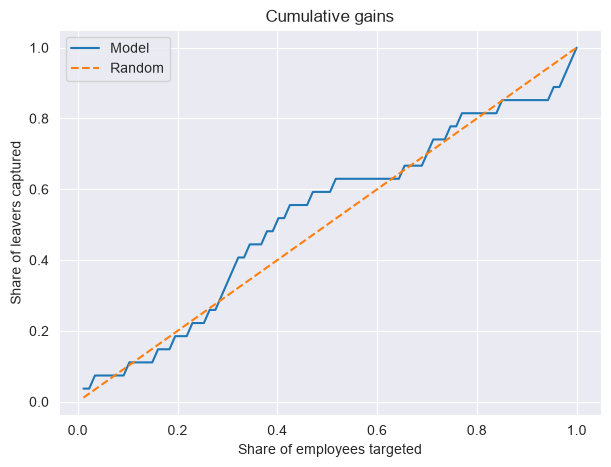

In [37]:
gains = gains_table(
    test_predictions["y_true"], test_predictions["y_proba"]
)
display(gains)

gains_curve = cumulative_gains_frame(
    test_predictions["y_true"], test_predictions["y_proba"]
)
plt.figure(figsize=(7, 5))
plt.plot(
    gains_curve["share_targeted"],
    gains_curve["share_captured"],
    label="Model",
)
plt.plot(
    gains_curve["share_targeted"],
    gains_curve["random_baseline"],
    linestyle="--",
    label="Random",
)
plt.xlabel("Share of employees targeted")
plt.ylabel("Share of leavers captured")
plt.title("Cumulative gains")
plt.legend()
plt.show()


**Capacity finding (held-out test set):**

| Employees targeted | Leavers captured | Share of leavers | Lift |
|---:|---:|---:|---:|
| 10% (9) | 3 | 11.1% | 1.11 |
| 20% (18) | 5 | 18.5% | 0.93 |
| 30% (27) | 10 | 37.0% | 1.23 |
| 50% (44) | 16 | 59.3% | 1.19 |

The top 20% captures **18.5%** of leavers, slightly *below* random (lift 0.93); at 30% and 50% the model beats random modestly (lift 1.23 and 1.19). The gains curve is not consistently above the diagonal, so the model is not ready for high-stakes targeting. Use it for analysis, data-collection prioritisation, and a baseline to beat — not for automated outreach.


# **BUSINESS RECOMMENDATION & LIMITATIONS**

## Business Recommendation

The gains analysis does **not** show a consistent lift over random targeting at the top 20% capacity, so the recommendations below are about analysis, process, and better data — not a production rollout.

1. **Rank, do not decide.** Use the probability and risk tier to order stay interviews and check-ins, and only after validating the ranking on a larger sample. Do not tell an employee they are "predicted to resign".
2. **Focus on the top tier first, then measure.** If HR pilots the score, choose a capacity (e.g. top 30%) and track how many of those employees actually leave over the next review cycle. The gains table is the acceptance test.
3. **Act on the controllable drivers.** Engagement and satisfaction scores, project participation, and absence patterns are more actionable than demographics. Demographics should not drive individual decisions.
4. **Close the data gap.** Compensation, manager quality, promotion velocity, commute, and exit-interview themes are the variables most likely to turn this into a strong model.
5. **Re-train after each cycle.** The dataset is a snapshot; attrition drivers change with the labour market and company policy.

## Limitations

- **Small sample:** 287 rows, 89 leavers. Estimates are noisy and the test set is only 87 rows.
- **Weak and unstable signal:** the tuned Decision Tree scores 0.661 CV ROC-AUC but 0.544 on the holdout split, and its gains curve is not consistently above random. It is not a high-confidence individual predictor.
- **Date inconsistency:** 64 of 89 leavers have an assessment date after their resignation date, so assessment-date features are unusable.
- **Correlation, not causation:** the top permutation-importance feature is age at hire; that does not mean age causes attrition.
- **Snapshot, not a time series:** the model predicts "has resigned" from a static profile, not "will resign in the next six months". A survival or time-to-event model would be the next step if dated snapshots become available.
- **No PII:** identifiers, phone numbers, and emails are excluded from the model and the artifact.


# **MODEL DEPLOYMENT**

## Build the Artifact

The notebook writes one versioned artifact. The Streamlit app loads it with `employee_attrition.pipeline.load_artifact` and never refits.


In [38]:
from datetime import datetime, timezone
from pathlib import Path

clean_all = clean_raw(df_raw)
clean_all_imputed = apply_imputation_values(clean_all, imputation_values)

default_values = {
    **{
        column: clean_all_imputed[column].mode().iloc[0]
        for column in schema.ORDINAL_COLUMNS + schema.NOMINAL_COLUMNS
    },
    **{
        column: float(clean_all_imputed[column].median())
        for column in schema.RAW_NUMERIC_COLUMNS
    },
    "TanggalLahir": str(
        pd.to_datetime(
            df_raw["TanggalLahir"], errors="coerce", format="mixed"
        ).median().date()
    ),
    "TanggalHiring": str(
        pd.to_datetime(
            df_raw["TanggalHiring"], errors="coerce", format="mixed"
        ).median().date()
    ),
}

base_date = pd.Timestamp("2005-01-01")


def build_example(index):
    row = clean_all_imputed.loc[index]
    age = float(row["UsiaSaatMasuk"])
    birth = base_date - pd.Timedelta(days=age * 365.25)
    example = {
        column: row[column] for column in schema.RAW_CATEGORICAL_COLUMNS
    }
    example.update(
        {
            column: float(row[column])
            for column in schema.RAW_NUMERIC_COLUMNS
        }
    )
    example["TanggalLahir"] = str(birth.date())
    example["TanggalHiring"] = str(base_date.date())
    return example


demo_raw = pd.DataFrame(
    [build_example(index) for index in clean_all_imputed.index]
)
demo_clean = clean_raw(demo_raw)
demo_clean = apply_imputation_values(demo_clean, imputation_values)
demo_encoded = align_features(
    encode_features(demo_clean, encoders=encoders)[0], feature_columns
)
demo_probabilities = selected_model.predict_proba(demo_encoded)[:, 1]

high_index = int(np.argmax(demo_probabilities))
low_index = int(np.argmin(demo_probabilities))
examples = {
    "high_risk": build_example(high_index),
    "low_risk": build_example(low_index),
}
print(
    f"High-risk profile: {demo_probabilities[high_index]:.3f} | "
    f"Low-risk profile: {demo_probabilities[low_index]:.3f}"
)

artifact = {
    "artifact_version": schema.ARTIFACT_VERSION,
    "created_at": datetime.now(timezone.utc).isoformat(),
    "model_name": selected_name,
    "model": selected_model,
    "encoders": encoders,
    "feature_columns": feature_columns,
    "numeric_columns": schema.NUMERIC_COLUMNS,
    "ordinal_columns": schema.ORDINAL_COLUMNS,
    "ordinal_categories": schema.ORDINAL_CATEGORIES,
    "nominal_columns": schema.NOMINAL_COLUMNS,
    "target_column": schema.TARGET_COLUMN,
    "target_labels": schema.TARGET_LABELS,
    "imputation_values": imputation_values,
    "default_values": default_values,
    "metrics": metrics,
    "training_summary": {
        "n_rows": int(len(df)),
        "n_train": int(len(X_train_enc)),
        "n_test": int(len(X_test_enc)),
        "positive_rate": float(y.mean()),
        "n_features": int(len(feature_columns)),
    },
    "test_predictions": test_predictions,
    "train_probabilities_sorted": [
        float(value) for value in sorted_train_proba
    ],
    "risk_tier_cutoffs": risk_tier_cutoffs,
    "examples": examples,
    "coefficients": coefficients,
    "permutation_importance": permutation_df,
}

model_path = Path("models/attrition_model.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(artifact, model_path)
print(
    f"Saved {model_path} ({model_path.stat().st_size / 1024:.1f} KB)"
)


High-risk profile: 0.600 | Low-risk profile: 0.120
Saved models\attrition_model.joblib (25.1 KB)


## Reload and Test a Single Prediction


In [39]:
loaded = load_artifact(model_path)
sample_raw = pd.DataFrame([examples["high_risk"]])
sample_probability = predict_proba(loaded, sample_raw)[0]
sample_encoded = transform_raw(loaded, sample_raw)
sample_explanation = explain_row(loaded, sample_encoded)

print(f"Reloaded artifact predicts: {sample_probability:.3f}")
display(sample_explanation)


Reloaded artifact predicts: 0.212


,feature,input,coefficient,contribution,direction


The reload test is the contract the Streamlit app depends on: the artifact must load from disk and score a raw row without any notebook state.

Because the deployed model is a Decision Tree (non-linear), `explain_row` returns an empty contribution table by design; the Streamlit app shows the model's global permutation-importance chart instead. A linear model would populate the table with coefficient × input contributions.

## Conclusion

This project delivers a complete, reproducible attrition pipeline and an honest model. The data does not support a high-confidence individual predictor: the tuned Decision Tree reaches 0.661 CV ROC-AUC but only 0.544 on the held-out split, catches 5 of 27 leavers at the default threshold, and does not beat random targeting at the top 20% capacity. The real value is the audit trail — the leakage policy, the weak-signal diagnosis, the honest gains analysis, and a deployable app that shows its uncertainty. The next iteration should collect the missing retention drivers (compensation, manager quality, promotion velocity, commute, exit interviews) and move to a time-aware snapshot or survival model.
